#  ENNAKHLA ZINEB 

## 1.3	Prise en main du jeu de données

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
import plotly.express as px
import scipy.stats

In [2]:
df = pd.read_csv("clients_marketing.csv")

Q1.1 Combien de clients (lignes) et de variables (colonnes) contient le jeu de données ?

In [3]:
df.shape

(1200, 18)

In [4]:
df.head()

,id_client,date_inscription,age,sexe,region,niveau_etude,revenu_mensuel,canal_acquisition,segment_client,nb_visites_mois,duree_session_min,nb_achats_an,panier_moyen,depense_annuelle,taux_ouverture_email,note_satisfaction,abonne_newsletter,reponse_campagne
0,CL0001,2025-05-29,34,Femme,Souss-Massa,Licence,6520.0,Moteur de recherche,Standard,9,6.4,7,337.01,2359.07,46.9,3,Oui,Oui
1,CL0002,2022-09-19,37,Femme,Marrakech-Safi,Bac,7600.0,Publicite TV,Premium,11,2.1,13,389.90,5068.70,13.0,5,Non,Non
2,CL0003,2022-02-08,38,Femme,Tanger-Tetouan,Licence,5940.0,Moteur de recherche,Standard,5,4.1,3,298.12,894.36,46.6,1,Oui,Non
3,CL0004,2024-07-23,34,Homme,Tanger-Tetouan,Bac,4960.0,Moteur de recherche,Standard,11,4.0,7,349.50,2446.50,29.6,4,Oui,Non
4,CL0005,2023-06-18,46,Femme,Rabat-Sale-Kenitra,Licence,4360.0,Moteur de recherche,Standard,15,2.8,5,307.97,1539.85,36.8,3,Oui,Non


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 18 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id_client             1200 non-null   object 
 1   date_inscription      1200 non-null   object 
 2   age                   1200 non-null   int64  
 3   sexe                  1200 non-null   object 
 4   region                1200 non-null   object 
 5   niveau_etude          1200 non-null   object 
 6   revenu_mensuel        1164 non-null   float64
 7   canal_acquisition     1200 non-null   object 
 8   segment_client        1200 non-null   object 
 9   nb_visites_mois       1200 non-null   int64  
 10  duree_session_min     1200 non-null   float64
 11  nb_achats_an          1200 non-null   int64  
 12  panier_moyen          1200 non-null   float64
 13  depense_annuelle      1200 non-null   float64
 14  taux_ouverture_email  1200 non-null   float64
 15  note_satisfaction    

In [6]:
df.describe()

,age,revenu_mensuel,nb_visites_mois,duree_session_min,nb_achats_an,panier_moyen,depense_annuelle,taux_ouverture_email,note_satisfaction
count,1200.000000,1164.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000
mean,36.685833,7999.639175,14.148333,5.895750,7.861667,430.218183,3369.445167,27.547750,3.235833
std,10.385022,3801.809662,4.054836,3.753658,3.346670,144.409469,1847.643490,13.669171,0.980315
min,18.000000,2110.000000,2.000000,0.300000,0.000000,116.590000,0.000000,0.000000,1.000000
25%,29.000000,5300.000000,11.000000,3.100000,5.000000,330.370000,2052.067500,17.500000,3.000000
50%,36.000000,7200.000000,14.000000,5.100000,8.000000,409.870000,3034.650000,26.800000,3.000000
75%,44.000000,9700.000000,17.000000,7.800000,10.000000,506.122500,4318.305000,38.500000,4.000000
max,70.000000,35740.000000,27.000000,26.500000,21.000000,1424.460000,12967.500000,64.000000,5.000000


In [7]:
df.columns

Index(['id_client', 'date_inscription', 'age', 'sexe', 'region',
       'niveau_etude', 'revenu_mensuel', 'canal_acquisition', 'segment_client',
       'nb_visites_mois', 'duree_session_min', 'nb_achats_an', 'panier_moyen',
       'depense_annuelle', 'taux_ouverture_email', 'note_satisfaction',
       'abonne_newsletter', 'reponse_campagne'],
      dtype='object')

In [8]:
df.isna().sum()

id_client                0
date_inscription         0
age                      0
sexe                     0
region                   0
niveau_etude             0
revenu_mensuel          36
canal_acquisition        0
segment_client           0
nb_visites_mois          0
duree_session_min        0
nb_achats_an             0
panier_moyen             0
depense_annuelle         0
taux_ouverture_email     0
note_satisfaction        0
abonne_newsletter        0
reponse_campagne         0
dtype: int64

In [9]:
df["revenu_mensuel"].describe()

count     1164.000000
mean      7999.639175
std       3801.809662
min       2110.000000
25%       5300.000000
50%       7200.000000
75%       9700.000000
max      35740.000000
Name: revenu_mensuel, dtype: float64

In [10]:
df.duplicated().sum()

np.int64(0)

In [175]:
df["date_inscription"].dtypes

dtype('O')

In [177]:
df["date_inscription"] = pd.to_datetime(df['date_inscription'], format='%Y-%m-%d')

In [13]:
print("date min :",df['date_inscription'].min())
print("date max :",df['date_inscription'].max())

date min : 2022-01-03
date max : 2025-12-31


In [14]:
niveau_etude_ordre = pd.Categorical(
    df['niveau_etude'],
    categories=['Primaire', 'Secondaire', 'Bac', 'Licence', 'Master', 'Doctorat'],
    ordered=True
)

segment_client_ordre = pd.Categorical(
    df['segment_client'],
    categories=['Client régulier', 'Client VIP', 'Client potentiel'],
    ordered=True
)

In [15]:
var_quanti = df.select_dtypes(include="number")

In [16]:
var_quanti

,age,revenu_mensuel,nb_visites_mois,duree_session_min,nb_achats_an,panier_moyen,depense_annuelle,taux_ouverture_email,note_satisfaction
0,34,6520.0,9,6.4,7,337.01,2359.07,46.9,3
1,37,7600.0,11,2.1,13,389.90,5068.70,13.0,5
2,38,5940.0,5,4.1,3,298.12,894.36,46.6,1
3,34,4960.0,11,4.0,7,349.50,2446.50,29.6,4
4,46,4360.0,15,2.8,5,307.97,1539.85,36.8,3
...,...,...,...,...,...,...,...,...,...
1195,52,6480.0,8,10.2,6,428.05,2568.30,20.3,2
1196,45,6990.0,21,9.2,13,395.91,5146.83,17.6,3
1197,26,3610.0,10,7.8,4,195.89,783.56,18.8,3
1198,46,11840.0,12,3.7,2,499.30,998.60,7.5,2


In [17]:
var_quali = df.select_dtypes(exclude="number")

In [18]:
var_quali

,id_client,date_inscription,sexe,region,niveau_etude,canal_acquisition,segment_client,abonne_newsletter,reponse_campagne
0,CL0001,2025-05-29,Femme,Souss-Massa,Licence,Moteur de recherche,Standard,Oui,Oui
1,CL0002,2022-09-19,Femme,Marrakech-Safi,Bac,Publicite TV,Premium,Non,Non
2,CL0003,2022-02-08,Femme,Tanger-Tetouan,Licence,Moteur de recherche,Standard,Oui,Non
3,CL0004,2024-07-23,Homme,Tanger-Tetouan,Bac,Moteur de recherche,Standard,Oui,Non
4,CL0005,2023-06-18,Femme,Rabat-Sale-Kenitra,Licence,Moteur de recherche,Standard,Oui,Non
...,...,...,...,...,...,...,...,...,...
1195,CL1196,2023-07-13,Homme,Rabat-Sale-Kenitra,Licence,Reseaux sociaux,Standard,Non,Non
1196,CL1197,2023-01-27,Femme,Rabat-Sale-Kenitra,Master,Email,Standard,Non,Non
1197,CL1198,2025-09-16,Homme,Casablanca-Settat,Bac,Moteur de recherche,Standard,Non,Non
1198,CL1199,2023-11-08,Femme,Casablanca-Settat,Licence,Reseaux sociaux,Premium,Oui,Non


### Q1.1 Combien de clients (lignes) et de variables (colonnes) contient le jeu de données ?

1 200 clients × 18 variables 

### Q1.2 Quel type Python pandas attribue-t-il à date_inscription à la lecture du CSV ? Pourquoi faut-il le convertir ?
il faut le convertir en datetime, pour éviter les erreurs de type et pouvoir analyser les dates correctement.
### Q1.3 Quelle(s) variable(s) contien(nen)t des valeurs manquantes ? Combien, et quel pourcentage ?
La variable revenu_mensuel contient 36 valeurs manquantes, soit 3 % des clients. 
### Q1.4 Y a-t-il des doublons ? id_client est-il bien unique ?
non y'a pas des doublons, 1 200 identifiants distincts.
## Q1.5 Quelle est la période couverte par les inscriptions ?
du 3 janvier 2022 au 31 décembre 2025 = 4 années


# 2.	Analyse univariée

In [19]:
var_quanti.columns

Index(['age', 'revenu_mensuel', 'nb_visites_mois', 'duree_session_min',
       'nb_achats_an', 'panier_moyen', 'depense_annuelle',
       'taux_ouverture_email', 'note_satisfaction'],
      dtype='object')

## 2.1	Variable quantitative continue : la dépense annuelle

### analyse de depense total annuelle

In [ ]:
#1.	Appliquer describe() à depense_annuelle ; noter n, moyenne, écart-type, min, Q1, médiane, Q3, max.
df["depense_annuelle"].describe()

count     1200.000000
mean      3369.445167
std       1847.643490
min          0.000000
25%       2052.067500
50%       3034.650000
75%       4318.305000
max      12967.500000
Name: depense_annuelle, dtype: float64

In [21]:
moyenne = df["depense_annuelle"].mean()
mediane = df["depense_annuelle"].median()
ecart_type = df["depense_annuelle"].std()
min = df["depense_annuelle"].min()
Q1 = df["depense_annuelle"].quantile(0.25)
Q3 = df["depense_annuelle"].quantile(0.75)
max = df["depense_annuelle"].max()

In [ ]:
#2.	Calculer le coefficient de variation : CV = écart-type / moyenne × 100.
CV = ecart_type / moyenne * 100
print("Coefficient de variation :", CV)

Coefficient de variation : 54.83524434721127


In [ ]:
#3.	Calculer l'écart interquartile IQR = Q3 − Q1, puis les bornes de Tukey : Q1 − 1,5×IQR et Q3 + 1,5×IQR.
IQR = Q3 - Q1

borne_inf = Q1 - 1.5 * IQR
borne_sup = Q3 + 1.5 * IQR

In [ ]:
#4.	Compter les clients en dehors de ces bornes (valeurs atypiques), en séparant les valeurs basses et hautes.
atypiques = df[(df['depense_annuelle'] < borne_inf) | (df['depense_annuelle'] > borne_sup)]
print("Nombre de clients atypiques :", len(atypiques))
print("En dessous :", (df['depense_annuelle'] < borne_inf).sum())
print("Au-dessus :", (df['depense_annuelle'] > borne_sup).sum())

Nombre de clients atypiques : 38
En dessous : 0
Au-dessus : 38


In [ ]:
#5.	Calculer le coefficient d'asymétrie (.skew()) et d'aplatissement (.kurt()).
asymetrie = df['depense_annuelle'].skew()
print("Coefficient d'asymétrie :", asymetrie)

aplatissement = df['depense_annuelle'].kurt()
print("Coefficient d'aplatissement :", aplatissement)

Coefficient d'asymétrie : 1.2679360069323276
Coefficient d'aplatissement : 2.625903034259863


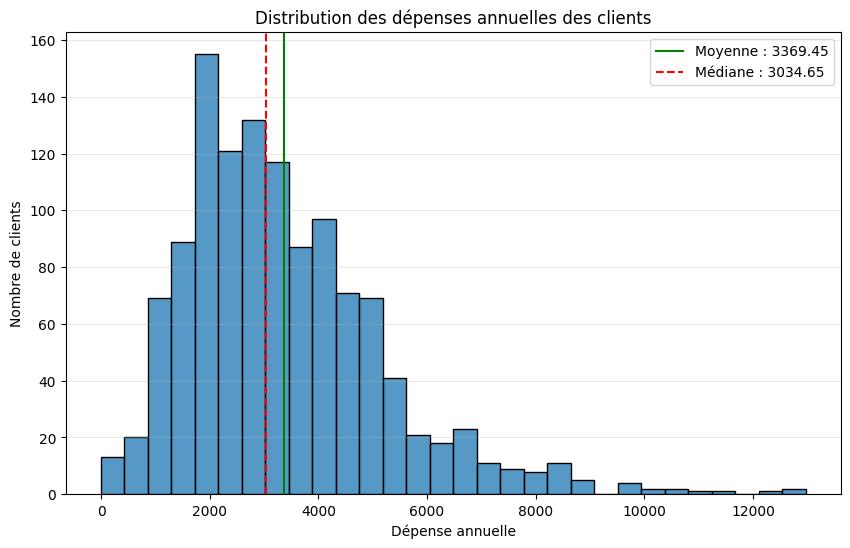

In [ ]:
#6.	Tracer un histogramme (30 classes) et y ajouter deux lignes verticales : la moyenne et la médiane.
plt.figure(figsize=(10, 6))
sns.histplot(df['depense_annuelle'], bins=30, kde=False)

plt.axvline(moyenne, color='green', linestyle='-',
            label=f'Moyenne : {moyenne:.2f}')
plt.axvline(mediane, color='red', linestyle='--',
            label=f'Médiane : {mediane:.2f}')
plt.title("Distribution des dépenses annuelles des clients")
plt.xlabel("Dépense annuelle")
plt.ylabel("Nombre de clients")
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.show()

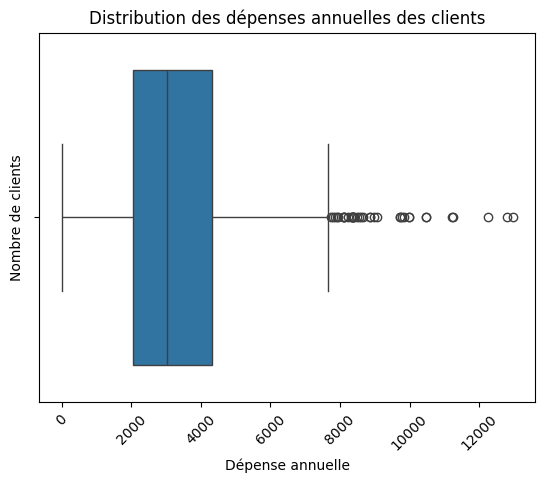

In [ ]:
#7.	Tracer une boîte à moustaches de la même variable, à côté de l'histogramme.
sns.boxplot(data=df, x="depense_annuelle")
plt.title("Distribution des dépenses annuelles des clients")
plt.xlabel("Dépense annuelle")
plt.ylabel("Nombre de clients")
plt.xticks(rotation=45)
plt.show()

### Q2.1.1 Quelles sont la moyenne et la médiane ? Laquelle est la plus grande et que cela signifie-t-il sur la forme de la distribution ?
D'apres 1 et 2 ,la moyenne = 3369.44 est superieure a la mediane = 3034.65 cela signifie que l'asymetrie est positive

### Q2.1.2 Quel est l'écart-type ? Le CV est-il faible (< 15 %), moyen (15–30 %) ou élevé (> 30 %) ?
D'apres 2 , l'ecart type = 1847.76 et le CV est élevé (55%)

### Q2.1.3 Combien de clients sont atypiques selon la règle de Tukey ? Sont-ils au-dessus ou en dessous ?
D'apres 3 - la regle de Tukey les clients atypiques sont 38 clients , au dessus de la borne haute 

### Q2.1.4 Le coefficient d'asymétrie est-il positif ou négatif ? Est-ce cohérent avec l'histogramme ? 
Le coefficient d'asymétrie est **positif** (≈ 1,27). C'est cohérent avec l'histogramme : les clients sont concentrés à gauche (petites dépenses) avec une longue queue à droite (quelques très grosses dépenses).

### Q2.1.5 Faut-il supprimer les valeurs atypiques ? Justifiez avec le contexte métier.

Non, il ne faut pas supprimer automatiquement les valeurs atypiques. Dans notre contexte métier, elles peuvent représenter des clients qui effectuent des dépenses annuelles très élevées, notamment des clients VIP ou à forte valeur commerciale.

### Q2.1.6 Quel indicateur de tendance centrale faut-il présenter au directeur marketing, et pourquoi ?

La **médiane (3 034,65)** est l'indicateur le plus pertinent à présenter au directeur marketing.

La médiane est préférable car elle est moins sensible aux valeurs atypiques et représente mieux le niveau de dépense d'un client typique.

## 2.2	Comparer deux distributions : âge (symétrique) et revenu(asymétrique)

In [ ]:
#1.	Calculer moyenne, médiane, écart-type, min, max et asymétrie de age et de revenu_mensuel.
moyenne_age = df['age'].mean()
mediane_age = df['age'].median()
ecart_type_age = df['age'].std()
min_age = df['age'].min()
max_age = df['age'].max()
asymetrie_age = df['age'].skew()

In [29]:
df["age"].describe()

count    1200.000000
mean       36.685833
std        10.385022
min        18.000000
25%        29.000000
50%        36.000000
75%        44.000000
max        70.000000
Name: age, dtype: float64

In [30]:
moyenne_revenu_mensuel = df['revenu_mensuel'].mean()
mediane_revenu_mensuel = df['revenu_mensuel'].median()
ecart_type_revenu_mensuel = df['revenu_mensuel'].std()
min_revenu_mensuel = df['revenu_mensuel'].min()
max_revenu_mensuel = df['revenu_mensuel'].max()
asymetrie_revenu_mensuel = df['revenu_mensuel'].skew()

In [31]:
df["revenu_mensuel"].describe()

count     1164.000000
mean      7999.639175
std       3801.809662
min       2110.000000
25%       5300.000000
50%       7200.000000
75%       9700.000000
max      35740.000000
Name: revenu_mensuel, dtype: float64

In [ ]:
#2.	Pour le revenu, vérifier combien de valeurs sont réellement utilisées (.count()) : pandas ignore les valeurs manquantes.
df["revenu_mensuel"].count()

np.int64(1164)

In [33]:
moyenne_revenu_mensuel - mediane_revenu_mensuel

np.float64(799.639175257732)

In [ ]:
#4.	Calculer les bornes de Tukey du revenu et compter les valeurs atypiques.
Q1_retenu = df['revenu_mensuel'].quantile(0.25)
Q3_retenu = df['revenu_mensuel'].quantile(0.75)

IQR_retenu = Q3_retenu - Q1_retenu

borne_sup = Q3_retenu + 1.5 * IQR_retenu
revenus_atypiques = df[df['revenu_mensuel'] > borne_sup]

print("Borne supérieure :", borne_sup)
print("Nombre de revenus atypiques :", len(revenus_atypiques))

Borne supérieure : 16300.0
Nombre de revenus atypiques : 41


### Q2.2.1 Pour quelle variable la moyenne et la médiane sont-elles presque égales ? Que peut-on en conclure ?
En se basant sur 1 Le moyenne et le median et presque égales pour la colonne d'age<br>On conclue que l'age est quasi symetrique
### Q2.2.2 Pour le revenu, de combien la moyenne dépasse-t-elle la médiane ? Quelle forme a la distribution ?
La moyenne (≈ 8 000 MAD) dépasse la médiane (7 200 MAD) de **≈ 800 MAD**. La distribution est asymétrique à droite : quelques revenus très élevés tirent la moyenne vers le haut.
### Q2.2.3 Combien de revenus sont atypiques (au-dessus de la borne haute) ?
D'apres 4 ,le Nombre de revenus atypiques : 41
### Q2.2.4 Pourquoi est-il préférable de parler du « revenu médian » plutôt que du « revenu moyen » dans un rapport ?
Il est préférable d'utiliser le revenu médian car les revenus présentent généralement une distribution asymétrique avec quelques valeurs très élevées.

## 2.3	Variable qualitative nominale : le canal d'acquisition

In [ ]:
#1.	Calculer les effectifs de chaque canal avec value_counts().
effectifs = df["canal_acquisition"].value_counts()
effectifs

canal_acquisition
Moteur de recherche    325
Reseaux sociaux        318
Email                  247
Parrainage             171
Publicite TV           139
Name: count, dtype: int64

In [ ]:
#2.	Calculer les fréquences en % avec value_counts(normalize=True) × 100 ; vérifier que le total fait 100 %.
frequences = df["canal_acquisition"].value_counts(normalize = True)*100
frequences

canal_acquisition
Moteur de recherche    27.083333
Reseaux sociaux        26.500000
Email                  20.583333
Parrainage             14.250000
Publicite TV           11.583333
Name: proportion, dtype: float64

In [ ]:
#3.	Réunir effectifs et pourcentages dans un seul tableau.
tableau_niveau = pd.DataFrame({
    'Effectif': effectifs,
    'Pourcentage (%)': frequences.round(2)
})
display(tableau_niveau)

,Effectif,Pourcentage (%)
canal_acquisition,,
Moteur de recherche,325,27.08
Reseaux sociaux,318,26.50
Email,247,20.58
Parrainage,171,14.25
Publicite TV,139,11.58


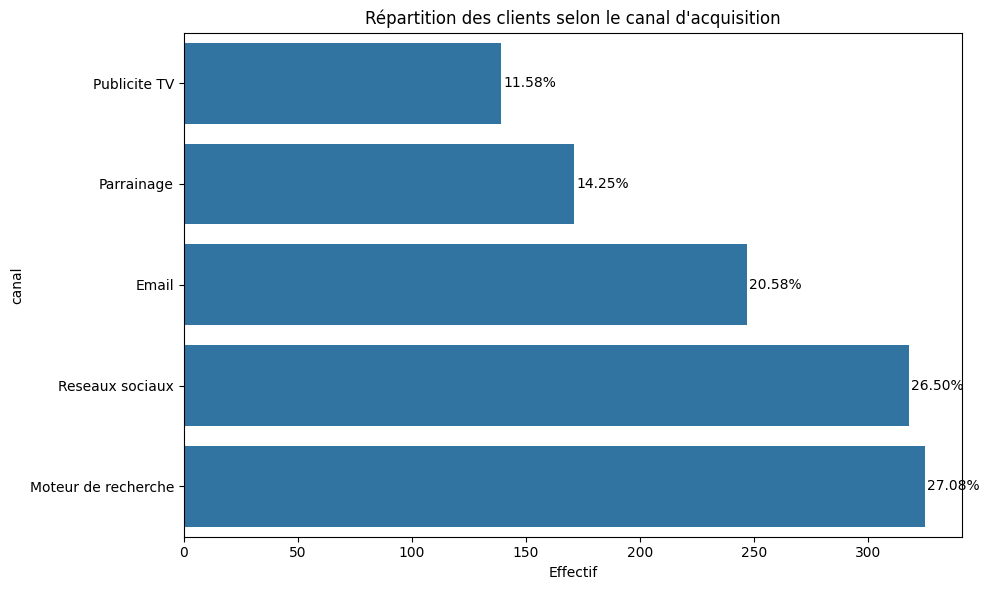

In [ ]:
#4.	Tracer un diagramme en barres horizontales trié du plus petit au plus grand, avec le % écrit au bout de chaque barre.
tableau_niveau = tableau_niveau.sort_values(
    by='Effectif',
    ascending=True
)
plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=tableau_niveau,
    x='Effectif',
    y=tableau_niveau.index)

for i, (effectif, pourcentage) in enumerate(
    zip(tableau_niveau['Effectif'],
        tableau_niveau['Pourcentage (%)'])
):
    ax.text(effectif + 1, i, f'{pourcentage:.2f}%',
            va='center')

plt.title("Répartition des clients selon le canal d'acquisition")
plt.xlabel("Effectif")
plt.ylabel("canal")
plt.tight_layout()
plt.show()

### Q2.3.1 Quel est le canal le plus fréquent (mode) ? Quelle est sa part ?
d'apres 1 le canal le plus frequent est le moteur de recherche de 27.08%
### Q2.3.2 Les deux premiers canaux sont-ils nettement différents ? Que représentent-ils ensemble ?
d'apres 3 (le pourcentage) et 4 (diagramme) le moteur de recherche (27,1%) et les reseaux sociaux (26.5%) sont presque égaux<br>Les deux ensemble presentent la moitie des clients (53.6%)

### Q2.3.3 Quel canal recrute le moins de clients ?

le diagramme montre que la publicite TV recrute le moins de clients

### Q2.3.4 Pourquoi la moyenne n'a-t-elle aucun sens pour cette variable ?

Car c'est un variable qualitative

##  2.3	Variable qualitative nominale : Region

In [ ]:
#5.1.	Refaire les étapes 1 à 4 pour region.
effectif_region = df["region"].value_counts()
frequence_region = df["region"].value_counts(normalize = True)*100
tableau_niveau_region = pd.DataFrame({
    'Effectif': effectif_region,
    'Pourcentage (%)': frequence_region.round(2)
})
display(tableau_niveau_region)

,Effectif,Pourcentage (%)
region,,
Casablanca-Settat,341,28.42
Rabat-Sale-Kenitra,246,20.50
Marrakech-Safi,207,17.25
Fes-Meknes,147,12.25
Tanger-Tetouan,138,11.50
Souss-Massa,121,10.08


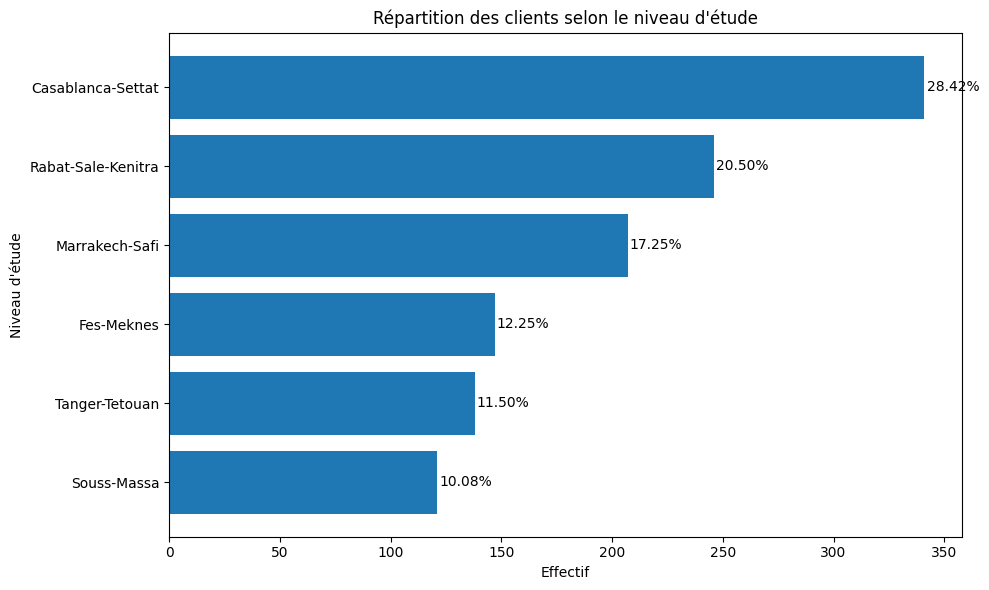

In [ ]:
#5.2.
tableau_niveau_region = tableau_niveau_region.sort_values(
    by='Effectif',
    ascending=True
)
plt.figure(figsize=(10, 6))
plt.barh(y=tableau_niveau_region.index, width=tableau_niveau_region['Effectif'])

for i, (effectif_region, pourcentage_region) in enumerate(
    zip(tableau_niveau_region['Effectif'],
        tableau_niveau_region['Pourcentage (%)'])
):
    plt.text(effectif_region + 1, i, f'{pourcentage_region:.2f}%',
             va='center')

plt.title("Répartition des clients selon le niveau d'étude")
plt.xlabel("Effectif")
plt.ylabel("Niveau d'étude")
plt.tight_layout()
plt.show()

### Q2.3.5 Quelle région concentre le plus de clients ? Quelle part de la clientèle se trouve hors Casablanca-Settat ?

D'après 5.1 et 5.2, la région qui concentre le plus de clients est **Casablanca-Settat (28,4 %)**. La part de la clientèle hors Casablanca-Settat est donc de **71,6 %**.

## 2.4	Variable qualitative ordinale : la satisfaction et le niveaud'étude

A.note de satisfaction

In [ ]:
#1.	Calculer les effectifs et les fréquences de note_satisfaction en les triant dans l'ordre des notes (sort_index()), pas par effectif.
ordre_notes = [1, 2, 3, 4, 5]

effectifs = df['note_satisfaction'].value_counts().reindex(ordre_notes, fill_value=0)
effectifs

note_satisfaction
1     41
2    223
3    470
4    344
5    122
Name: count, dtype: int64

In [42]:
frequences = effectifs / effectifs.sum()
frequences

note_satisfaction
1    0.034167
2    0.185833
3    0.391667
4    0.286667
5    0.101667
Name: count, dtype: float64

In [ ]:
#2.	Ajouter une colonne de fréquences cumulées (cumsum()).
frequences_cumulees = frequences.cumsum()
frequences_cumulees

note_satisfaction
1    0.034167
2    0.220000
3    0.611667
4    0.898333
5    1.000000
Name: count, dtype: float64

In [44]:
table_satisfaction = pd.DataFrame({
    'Effectifs': effectifs,
    'Fréquences': frequences,
    'Fréquences cumulées': frequences_cumulees
})

display(table_satisfaction)

,Effectifs,Fréquences,Fréquences cumulées
note_satisfaction,,,
1,41,0.034167,0.034167
2,223,0.185833,0.220000
3,470,0.391667,0.611667
4,344,0.286667,0.898333
5,122,0.101667,1.000000


In [ ]:
#3.	Déterminer le mode et la médiane (la modalité où la fréquence cumulée dépasse 50 %).
df['note_satisfaction'].mode()

0    3
Name: note_satisfaction, dtype: int64

In [46]:
df['note_satisfaction'].median()

np.float64(3.0)

In [ ]:
#4.	Calculer la part de clients satisfaits (notes 4 et 5) et insatisfaits (notes 1 et 2).
satisfaits = df['note_satisfaction'].isin([4, 5]).sum()
pourcentage_satisfaits = satisfaits / len(df) * 100
print(f"Clients satisfaits : {pourcentage_satisfaits:.2f} %")

Clients satisfaits : 38.83 %


In [48]:
insatisfaits = df['note_satisfaction'].isin([1, 2]).sum()
pourcentage_insatisfaits = insatisfaits / len(df) * 100
print(f"Clients insatisfaits : {pourcentage_insatisfaits:.2f} %")

Clients insatisfaits : 22.00 %


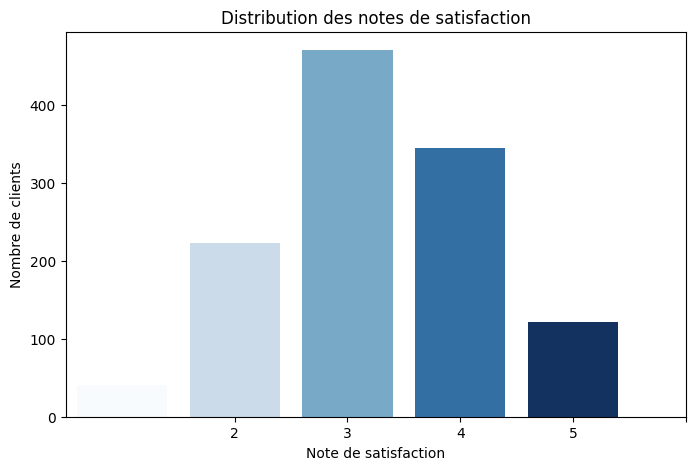

In [ ]:
#5.	Tracer un diagramme en barres dans l'ordre 1 → 5 (une couleur de plus en plus foncée est un bon choix pour suggérer l'ordre).
plt.figure(figsize=(8, 5))

sns.barplot(
    data=table_satisfaction.reset_index(),
    x='note_satisfaction',
    y='Effectifs',
    hue='note_satisfaction',
    order=[1, 2, 3, 4, 5],
    palette='Blues',
    legend=False
)

plt.title("Distribution des notes de satisfaction")
plt.xlabel("Note de satisfaction")
plt.ylabel("Nombre de clients")
plt.xticks([1, 2, 3, 4, 5])

plt.show()

B.niveau_etude 

In [ ]:
#6.1	Refaire les étapes 1 à 3 pour niveau_etude dans l'ordre Bac → Licence → Master → Doctorat.
ordre_etudes = ['Bac', 'Licence', 'Master', 'Doctorat']

effectifs_etudes = df['niveau_etude'].value_counts().reindex(ordre_etudes, fill_value=0)
effectifs_etudes

niveau_etude
Bac         326
Licence     445
Master      343
Doctorat     86
Name: count, dtype: int64

In [51]:
frequences_etudes = effectifs_etudes / effectifs_etudes.sum()
frequences_etudes

niveau_etude
Bac         0.271667
Licence     0.370833
Master      0.285833
Doctorat    0.071667
Name: count, dtype: float64

In [ ]:
#6.2
frequences_cumulees_etudes = frequences_etudes.cumsum()
frequences_cumulees_etudes

niveau_etude
Bac         0.271667
Licence     0.642500
Master      0.928333
Doctorat    1.000000
Name: count, dtype: float64

In [ ]:
#6.3
df['niveau_etude'].mode()

0    Licence
Name: niveau_etude, dtype: object

In [54]:
mediane_etudes = frequences_cumulees_etudes[
    frequences_cumulees_etudes >= 0.5
].index[0]
mediane_etudes

'Licence'

### Q2.4.1 Quelle note est la plus fréquente ? Quelle est la note médiane ?

d'apres 2 et 3 La note la plus frequente est *3*<br>la note mediane est la premiere note pour laquelle la frequence cumulee atteint ou depasse 50% : *3*

### Q2.4.2 Quel pourcentage de clients est satisfait (4–5) ? insatisfait (1–2) ?

d'apres 4 :<br>Clients satisfaits : 38.83 %
Clients insatisfaits : 22.00 %

### Q2.4.3 La moyenne des notes est 3,24 : pourquoi faut-il la présenter avec prudence ?

La note de satisfaction est une variable qualitative ordinale. Les notes possèdent un ordre, mais on ne peut pas garantir que l'écart entre 1 et 2 est équivalent à celui entre 4 et 5. La moyenne de 3,24 doit donc être interprétée avec prudence. La médiane, le mode et les fréquences sont plus adaptés.

### Q2.4.4 Quel est le niveau d'étude médian des clients ? Quelle part a au moins un Master ?

le niveau d'etude median des clients et la licence<br>
La part ayant au moins un Master correspond aux clients ayant un niveau Master ou Doctorat

## 2.5 Variables binaires : taux de réponse et taux d'abonnement

In [ ]:
#1.	Calculer le nombre et le pourcentage de « Oui » pour reponse_campagne et abonne_newsletter.
nb_reponses = (df['reponse_campagne'] == 'Oui').sum()
print(f"Nombre de réponses Oui : {nb_reponses}")

Nombre de réponses Oui : 256


In [ ]:
#2.	Présenter ces deux taux sous forme de chiffres clés 
taux_reponse = (nb_reponses /  len(df)) * 100
print(f"Taux de réponse : {taux_reponse:.2f} %")

Taux de réponse : 21.33 %


In [57]:
nb_abonnes = (df['abonne_newsletter'] == 'Oui').sum()
print(f"Nombre d'abonnés : {nb_abonnes}")

Nombre d'abonnés : 579


In [58]:
taux_abonnement = (nb_abonnes / len(df)) * 100
print(f"Taux d'abonnement : {taux_abonnement:.2f} %")

Taux d'abonnement : 48.25 %


In [59]:
print("=" * 40)
print("          CHIFFRES CLÉS")
print("=" * 40)

print(f"Taux de réponse : {taux_reponse:.2f} %")
print(f"Taux d'abonnement : {taux_abonnement:.2f} %")

print("=" * 40)

          CHIFFRES CLÉS
Taux de réponse : 21.33 %
Taux d'abonnement : 48.25 %


### Q2.5.1 – Quel est le taux de réponse global à la dernière campagne ?

les chiffres cles montre que le Taux de réponse global de clients ayant repondu OUi : 21.33 %


### Q2.5.2 Quelle part des clients est abonnée à la newsletter ?

48.25 % est la part des clients abonne a la newsletter et prend la valeur OUI

### Q2.5.3 Pourquoi le taux de réponse global sera-t-il la référence dans la partie bivariée ?

Le taux de réponse global représente le taux moyen de réponse de l'ensemble des clients. Il sert de référence pour comparer les taux de réponse entre différents groupes de clients

# 3.	Analyse bivariée

## 3.1	Quantitative × Quantitative : corrélation

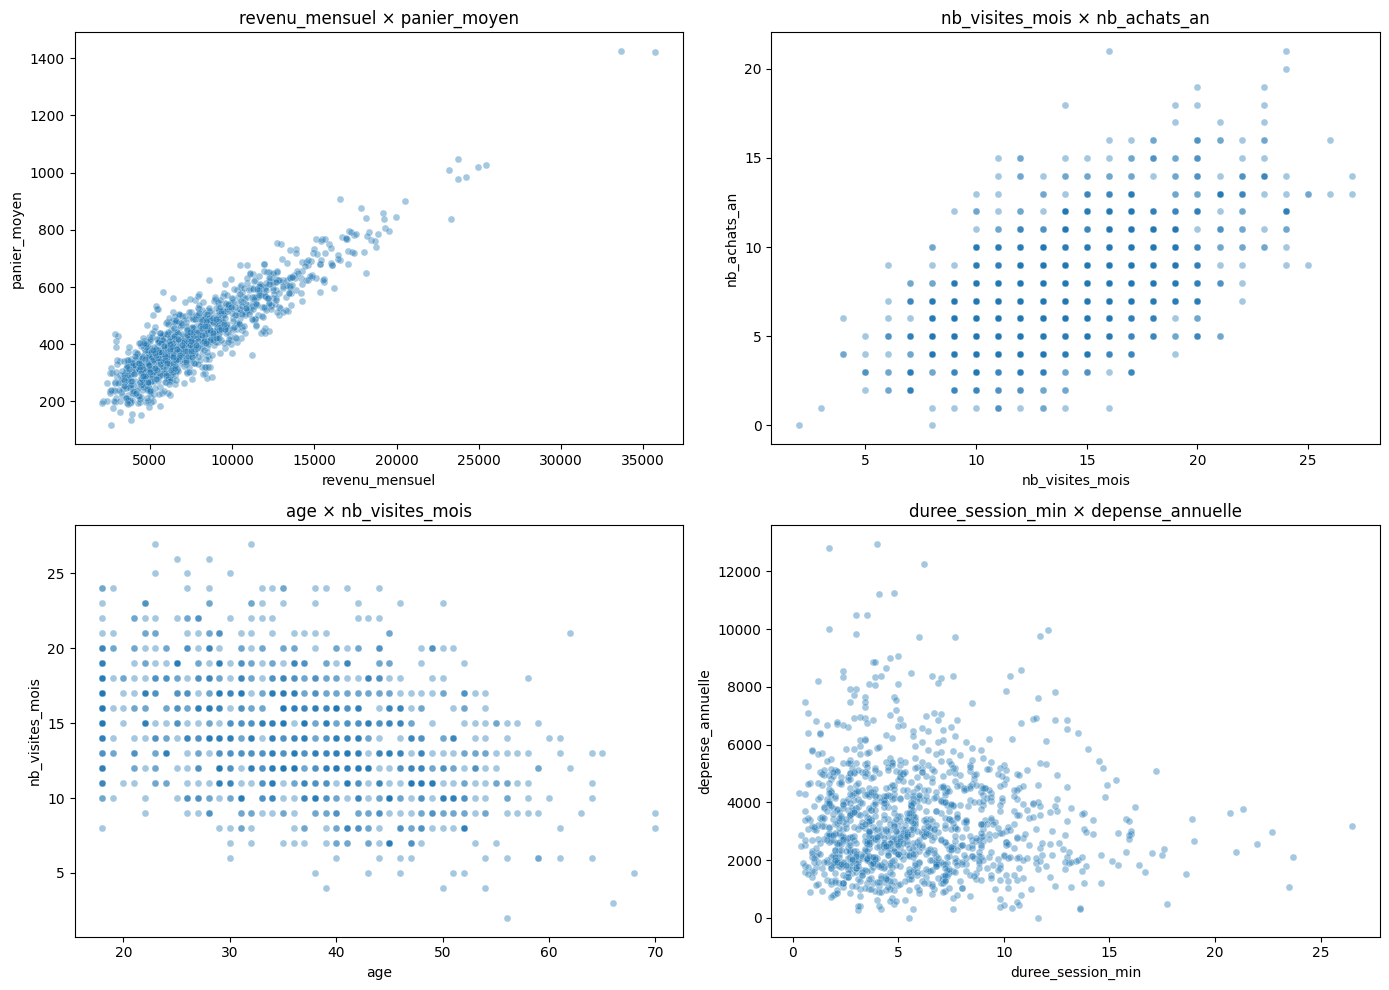

In [ ]:
#1.	Pour chacun des 4 couples ci-dessous, tracer un nuage de points (petits points, transparence alpha=0.4).
couples = [
    ('revenu_mensuel', 'panier_moyen'),
    ('nb_visites_mois', 'nb_achats_an'),
    ('age', 'nb_visites_mois'),
    ('duree_session_min', 'depense_annuelle')
]
resultats = []

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, (x, y) in zip(axes.flatten(), couples):

    data = df[[x, y]].dropna()

    sns.scatterplot(
        data=data,
        x=x,
        y=y,
        alpha=0.4,
        s=25,
        ax=ax
    )

    ax.set_title(f'{x} × {y}')

plt.tight_layout()
plt.show()

In [ ]:
#3.	Calculer le coefficient de Pearson (stats.pearsonr) et celui de Spearman (stats.spearmanr) avec leurs p-values.
from scipy import stats
pearson_r, pearson_p = stats.pearsonr(data[x], data[y])

spearman_r, spearman_p = stats.spearmanr(data[x], data[y])

print(f"Pearson : {pearson_r:.4f} | p-value : {pearson_p:.6f}")
print(f"Spearman : {spearman_r:.4f} | p-value : {spearman_p:.6f}")

Pearson : -0.0411 | p-value : 0.154556
Spearman : -0.0151 | p-value : 0.600218


In [62]:
# Supprimer les valeurs manquantes
data = df[['revenu_mensuel', 'panier_moyen']].dropna()

x = data['revenu_mensuel']
y = data['panier_moyen']

# Calculer la pente et l'ordonnée à l'origine
a, b = np.polyfit(x, y, 1)

# Valeurs prédites
y_pred = a * x + b

# Calcul de R²
r2 = 1 - (
    np.sum((y - y_pred)**2) /
    np.sum((y - y.mean())**2)
)

print(f"Pente : {a:.4f}")
print(f"Ordonnée à l'origine : {b:.2f}")
print(f"Équation : panier_moyen = {b:.2f} + {a:.4f} × revenu_mensuel")
print(f"R² : {r2:.3f}")

Pente : 0.0348
Ordonnée à l'origine : 152.94
Équation : panier_moyen = 152.94 + 0.0348 × revenu_mensuel
R² : 0.829


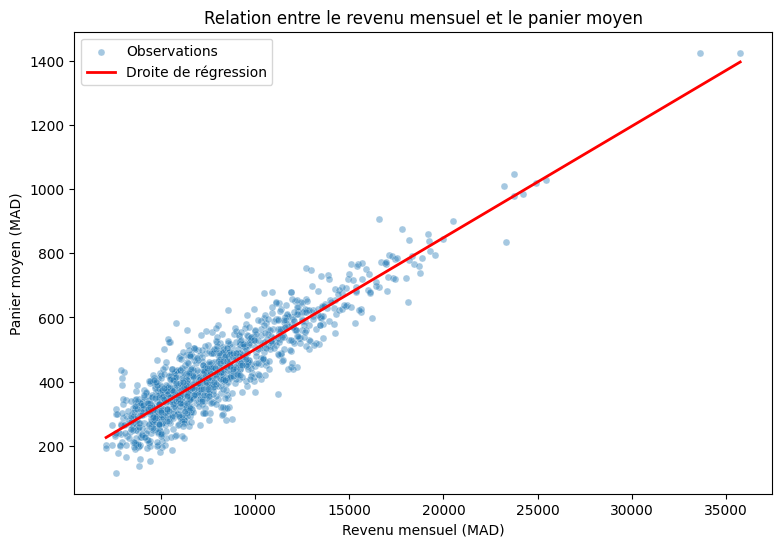

In [ ]:
#4.	Pour le couple le plus corrélé, ajuster une droite de régression (np.polyfit(x, y, 1)), la tracer, et calculer r².
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=data,
    x='revenu_mensuel',
    y='panier_moyen',
    alpha=0.4,
    s=25,
    label='Observations'
)

# Trier les valeurs pour tracer correctement la droite
x_sorted = np.sort(x)

plt.plot(
    x_sorted,
    a * x_sorted + b,
    color='red',
    linewidth=2,
    label='Droite de régression'
)

plt.title("Relation entre le revenu mensuel et le panier moyen")
plt.xlabel("Revenu mensuel (MAD)")
plt.ylabel("Panier moyen (MAD)")
plt.legend()
plt.show()

In [64]:
resultats = []

couples = [
    ('revenu_mensuel', 'panier_moyen'),
    ('nb_visites_mois', 'nb_achats_an'),
    ('age', 'nb_visites_mois'),
    ('duree_session_min', 'depense_annuelle')
]

for x, y in couples:

    data = df[[x, y]].dropna()

    pearson_r, pearson_p = stats.pearsonr(data[x], data[y])
    spearman_r, spearman_p = stats.spearmanr(data[x], data[y])

    resultats.append({
        'Couple': f'{x} × {y}',
        'N': len(data),
        'Pearson': pearson_r,
        'Spearman': spearman_r,
        'p-value': pearson_p
    })

table_correlations = pd.DataFrame(resultats)

print(table_correlations.columns.tolist())
display(table_correlations.round(3))

['Couple', 'N', 'Pearson', 'Spearman', 'p-value']


,Couple,N,Pearson,Spearman,p-value
0,revenu_mensuel × panier_moyen,1164,0.911,0.861,0.000
1,nb_visites_mois × nb_achats_an,1200,0.568,0.547,0.000
2,age × nb_visites_mois,1200,-0.375,-0.368,0.000
3,duree_session_min × depense_annuelle,1200,-0.041,-0.015,0.155


In [ ]:
#5.	Classer chaque couple avec la grille : |r| < 0,2 très faible / nul ; 0,2–0,4 faible ; 0,4–0,6 modéré ; 0,6–0,8 fort ; > 0,8 très fort.
def interpretation(r):

    valeur = abs(r)

    if valeur < 0.2:
        force = "Très faible"
    elif valeur < 0.4:
        force = "Faible"
    elif valeur < 0.6:
        force = "Modérée"
    elif valeur < 0.8:
        force = "Forte"
    else:
        force = "Très forte"

    if r > 0:
        sens = "Positive"
    elif r < 0:
        sens = "Négative"
    else:
        sens = "Nulle"

    return f"{sens}, {force}"


table_correlations['Conclusion'] = table_correlations['Pearson'].apply(interpretation)

display(table_correlations.round(3))

,Couple,N,Pearson,Spearman,p-value,Conclusion
0,revenu_mensuel × panier_moyen,1164,0.911,0.861,0.000,"Positive, Très forte"
1,nb_visites_mois × nb_achats_an,1200,0.568,0.547,0.000,"Positive, Modérée"
2,age × nb_visites_mois,1200,-0.375,-0.368,0.000,"Négative, Faible"
3,duree_session_min × depense_annuelle,1200,-0.041,-0.015,0.155,"Négative, Très faible"


### Q3.1.1 Pour chaque couple, donnez le sens (positif / négatif) et la force de la relation.

d'apres les nuages des points et la table de correlations
**Revenu mensuel × Panier moyen** : corrélation positive très forte (Pearson = 0,911). Plus le revenu augmente, plus le panier moyen tend à augmenter<br>

**Nombre de visites × Nombre d'achats** : corrélation positive modérée (Pearson = 0,568). Les clients qui visitent davantage ont tendance à effectuer plus d'achats.<br>

**Âge × Nombre de visites** : corrélation négative faible (Pearson = -0,375). Les visites tendent à diminuer avec l'âge.<br>

**Durée de session × Dépense annuelle** : corrélation très faible (Pearson = -0,041). Il n'existe pas de relation linéaire significative entre ces deux variables.

### Q3.1.2 Le couple (d) est-il significatif ? Que conclure pour l'équipe qui voulait « augmenter le temps passé sur le site pour vendre plus » ?

en se basant sur le tableau de correlation:
Non. La corrélation est très faible (-0,041) et la p-value est de 0,155 > 0,05

On ne peut pas conclure à une relation statistiquement significative entre la durée de session et la dépense annuelle.

### Q3.1.3 Pour le couple (a), interprétez la pente : de combien augmente le panier moyen quand le revenu augmente de 1 000 MAD ?

Le couple a presente une correlation forte, lorsque le revenu mensuel augmente de 1 000 MAD, le panier moyen augmente en moyenne d'environ 34,8 MAD (Pente : 0.0348
)

### Q3.1.4 Que représente r² pour le couple (a) ?

R² = 0,83 est le coefficient de détermination <br>
montre une association statistique et non une relation de causalité.

### Q3.1.5 Pourquoi Pearson et Spearman donnent-ils des valeurs proches ici ? Dans quel cas préférer Spearman ?

Les coefficients de Pearson et Spearman sont assez proches pour les trois premiers couples car les relations observées sont globalement monotones et relativement proches d'une relation linéaire.<br>
Spearman est preferable en présence de valeurs extrêmes ou de relations non linéaires mais monotones.

## 3.2	Qualitative × Quantitative : comparaison de groupes

### A. segment_client × depense_annuelle 

In [ ]:
#1.	Calculer, pour chaque modalité de la variable qualitative : effectif, moyenne, médiane et écart-type de la variable quantitative (groupby().agg()).
groupA = df.groupby('segment_client')['depense_annuelle'].agg(
    Effectif='count',
    Moyenne='mean',
    Mediane='median',
    Ecart_type='std'
)

display(groupA.round(2))

,Effectif,Moyenne,Mediane,Ecart_type
segment_client,,,,
Premium,458,3626.98,3405.70,1625.15
Standard,580,2667.19,2403.89,1346.62
VIP,162,5155.60,4744.47,2495.88


<Axes: xlabel='segment_client', ylabel='depense_annuelle'>

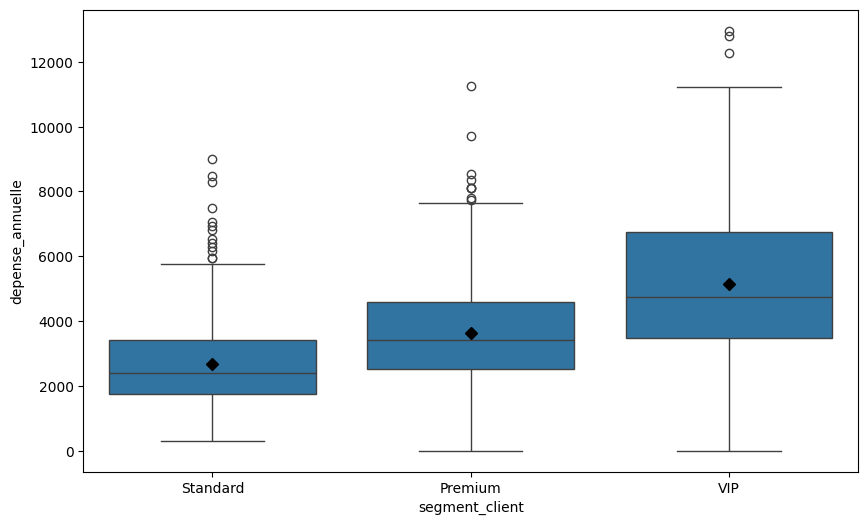

In [ ]:
#2.	Tracer des boîtes à moustaches par groupe (dans l'ordre logique des modalités pour une variable ordinale), en ajoutant la moyenne.
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df,
    x='segment_client',
    y='depense_annuelle',
    showmeans = True,
    meanprops={"marker": "D", "markerfacecolor": "black", "markeredgecolor": "black"}
)

In [ ]:
#3.	Comparer les groupes avec une ANOVA à un facteur (stats.f_oneway) si ≥ 3 groupes, ou un t de Welch (stats.ttest_ind(..., equal_var=False)) si 2 groupes.
from scipy.stats import f_oneway

groupA = [
    group["depense_annuelle"].dropna()
    for _, group in df.groupby("segment_client")
]

f_stat, p_value = f_oneway(*groupA)

print("F-statistic :", f_stat)
print("P-value :", p_value)

if p_value < 0.05:
    print("Le dépense annuelle varie significativement selon le segment de client.")
else:
    print("Aucune différence significative détectée.")

F-statistic : 152.98178463678818
P-value : 6.850140143030214e-60
Le dépense annuelle varie significativement selon le segment de client.


In [ ]:
# 4. Calculer l'intensité avec η² = SC / SC 
dataA = df[['segment_client', 'depense_annuelle']].dropna()

moyenne_generale = dataA['depense_annuelle'].mean()

SC_inter = sum(
    len(groupe) * (groupe.mean() - moyenne_generale)**2
    for _, groupe in dataA.groupby('segment_client')['depense_annuelle']
)

SC_totale = (
    (dataA['depense_annuelle'] - moyenne_generale)**2
).sum()

eta2_A = SC_inter / SC_totale

print("Eta² :", round(eta2_A, 3))

Eta² : 0.204


### Q3.2.1 Cas A : classez les segments par dépense moyenne. Le VIP dépense combien de fois plus que le Standard (en moyenne) ?
D'apres la calcul des moyens, les clients standards depensent moins que les premiums moins que VIP 
Le VIP (5155.6) depense presque 2 fois que le Standard (2667.2)
### Q3.2.2 Cas A : l'ANOVA est-elle significative ? Quelle part de la variabilité de la dépense est expliquée par le segment ? 
L'ANOVA montre que le dépense annuelle varie significativement selon le segment de client
puisque le segment de client augmente de standard a VIP , le depense anuelle augmente


### B. canal_acquisition × depense_annuelle 

In [ ]:
#1.
groupB = df.groupby('canal_acquisition')['depense_annuelle'].agg(
    Effectif='count',
    Moyenne='mean',
    Mediane='median',
    Ecart_type='std'
)

display(groupB.round(2))

,Effectif,Moyenne,Mediane,Ecart_type
canal_acquisition,,,,
Email,247,3350.60,2957.43,1933.94
Moteur de recherche,325,3306.47,3106.26,1752.97
Parrainage,171,3364.52,2970.17,1892.82
Publicite TV,139,3350.96,2844.31,1902.22
Reseaux sociaux,318,3459.17,3051.29,1832.96


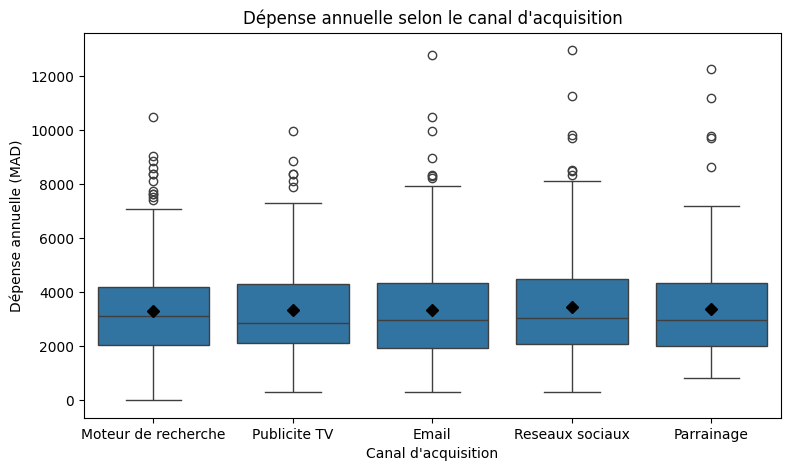

In [ ]:
#2. 
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='canal_acquisition',
    y='depense_annuelle',
    showmeans=True,
    meanprops={"marker": "D", "markerfacecolor": "black", "markeredgecolor": "black"}
)  

plt.title("Dépense annuelle selon le canal d'acquisition")
plt.xlabel("Canal d'acquisition")
plt.ylabel("Dépense annuelle (MAD)")
plt.show()

In [ ]:
#3.
groupB = [
    group["depense_annuelle"].dropna()
    for _, group in df.groupby("canal_acquisition")
]

f_stat, p_value = f_oneway(*groupB)

print("F-statistic :", f_stat)
print("P-value :", p_value)

if p_value < 0.05:
    print("Le dépense annuelle varie significativement selon le canal d'acquisition.")
else:
    print("Aucune différence significative détectée.")

F-statistic : 0.291377657872576
P-value : 0.8836776491875248
Aucune différence significative détectée.


In [ ]:
#4.
dataB = df[['canal_acquisition', 'depense_annuelle']].dropna()

moyenne_generale = dataB['depense_annuelle'].mean()

SC_inter = sum(
    len(groupe) * (groupe.mean() - moyenne_generale)**2
    for _, groupe in dataB.groupby('canal_acquisition')['depense_annuelle']
)

SC_totale = (
    (dataB['depense_annuelle'] - moyenne_generale)**2
).sum()

eta2_A = SC_inter / SC_totale

print("Eta² :", round(eta2_A, 3))

Eta² : 0.001


### Q3.2.3 Cas B : la dépense dépend-elle du canal d'acquisition ? Justifiez avec la p-value et η².
La dépense ne dépend pas du canal d'acquisition <br>D'après l'ANOVA, la p-value est > 0,05 : aucune différence significative n'est détectée, et l'effet η² est très faible (0,001).

### C. reponse_campagne × taux_ouverture_email.

In [ ]:
#1
groupC = df.groupby('reponse_campagne')['taux_ouverture_email'].agg(
    Effectif='count',
    Moyenne='mean',
    Mediane='median',
    Ecart_type='std'
)

display(groupC.round(2))

,Effectif,Moyenne,Mediane,Ecart_type
reponse_campagne,,,,
Non,944,25.79,24.90,13.36
Oui,256,34.03,36.15,12.83


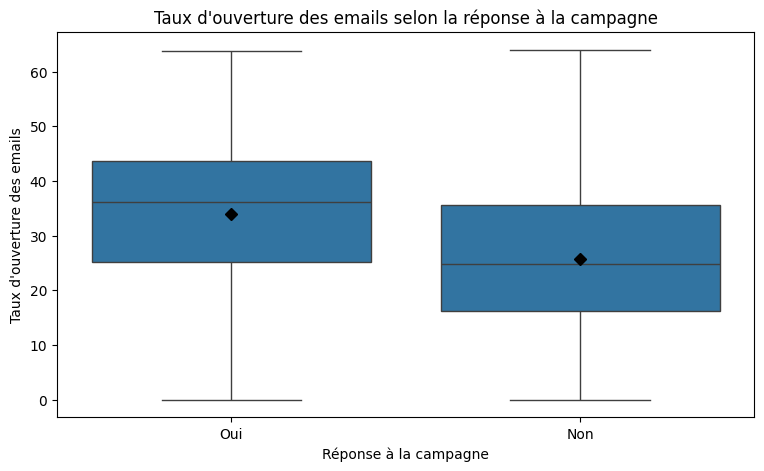

In [ ]:
#2
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='reponse_campagne',
    y='taux_ouverture_email',
    showmeans=True,
    meanprops={"marker": "D", "markerfacecolor": "black", "markeredgecolor": "black"}
)  

plt.title("Taux d'ouverture des emails selon la réponse à la campagne")
plt.xlabel("Réponse à la campagne")
plt.ylabel("Taux d'ouverture des emails")
plt.show()

In [ ]:
#3
groupe_oui = df.loc[df['reponse_campagne'] == 'Oui','taux_ouverture_email'].dropna()

groupe_non = df.loc[df['reponse_campagne'] == 'Non','taux_ouverture_email'].dropna()

t_stat, p_C = stats.ttest_ind(groupe_oui,groupe_non,equal_var=False)

print("Statistique t :", round(t_stat, 3))
print("P-value :", round(p_C, 5))
print("Moyenne Oui :", round(groupe_oui.mean(), 2))
print("Moyenne Non :", round(groupe_non.mean(), 2))

Statistique t : 9.032
P-value : 0.0
Moyenne Oui : 34.03
Moyenne Non : 25.79


In [ ]:
#4
dataC = df[['reponse_campagne', 'taux_ouverture_email']].dropna()

moyenne_generale = dataC['taux_ouverture_email'].mean()

SC_inter = sum(
    len(groupe) * (groupe.mean() - moyenne_generale)**2
    for _, groupe in dataC.groupby('reponse_campagne')['taux_ouverture_email']
)

SC_totale = (
    (dataC['taux_ouverture_email'] - moyenne_generale)**2
).sum()

eta2_A = SC_inter / SC_totale

print("Eta² :", round(eta2_A, 3))

Eta² : 0.061


### Q3.2.4 Cas C : les clients qui ont répondu à la campagne ouvrent-ils plus leurs emails ? La différence est-elle significative ?
D'apres 1 ,les repondants ouvrent les emails plus que les non repondants , et l'intensite moyenne
### Q3.2.5 Pourquoi les boxplots sont-ils plus informatifs qu'un simple diagramme des moyennes ?
les boxplots sont plus informatifs car ils presentent plusieurs informations (moyennes, max, min , median) et plus claire pour la comparaison

## 3.3	Qualitative × Qualitative : tableau croisé et khi-deux

### A. canal_acquisition × reponse_campagne 

In [ ]:
#1.	Construire le tableau croisé des effectifs avec pd.crosstab.
tableauA = pd.crosstab(df['canal_acquisition'], df['reponse_campagne'])
tableauA

reponse_campagne,Non,Oui
canal_acquisition,,
Email,174,73
Moteur de recherche,252,73
Parrainage,127,44
Publicite TV,127,12
Reseaux sociaux,264,54


In [ ]:
#2.	Calculer les profils-lignes (% en ligne, normalize='index') : pour chaque canal, quel % a répondu « Oui » ?
tableauAp = pd.crosstab(df['canal_acquisition'], df['reponse_campagne'], normalize='index')
tableauAp.round(2)

reponse_campagne,Non,Oui
canal_acquisition,,
Email,0.70,0.30
Moteur de recherche,0.78,0.22
Parrainage,0.74,0.26
Publicite TV,0.91,0.09
Reseaux sociaux,0.83,0.17


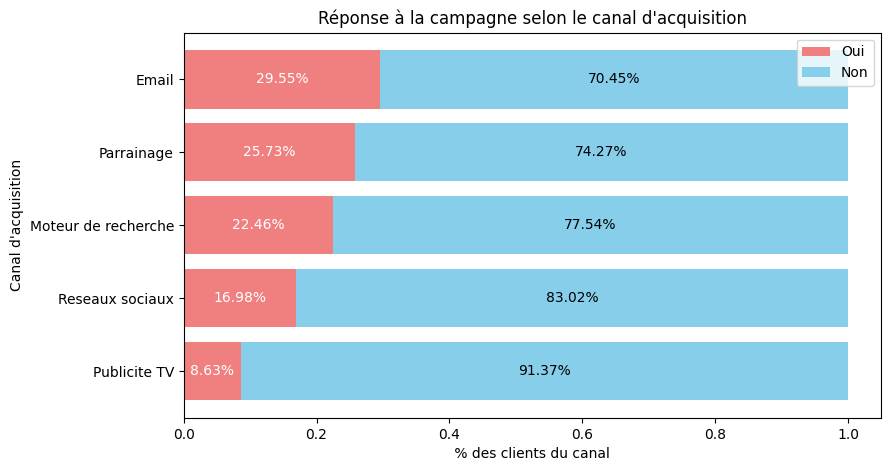

In [ ]:
#3.	Tracer un diagramme en barres empilées à 100 % (ou une barre par groupe représentant le % de « Oui »), trié.
oui = tableauAp['Oui'].sort_values(ascending=True)
non = tableauAp['Non'].sort_values(ascending=False)
plt.figure(figsize=(9, 5))
plt.barh(
    y=oui.index,
    width=oui.values,
    color='lightcoral'
)
plt.barh(
    y=non.index,
    width=non.values,
    left=oui.values,
    color='skyblue'
)
for i in range(len(oui)):
    plt.text(
        oui.values[i] / 2,
        i,
        f"{oui.values[i]:.2%}",
        ha='center',
        va='center',
        color='white',
        fontsize=10
    )
    plt.text(
        oui.values[i] + non.values[i] / 2,
        i,
        f"{non.values[i]:.2%}",
        ha='center',
        va='center',
        color='black',
        fontsize=10
    )
plt.title("Réponse à la campagne selon le canal d'acquisition")
plt.xlabel(" % des clients du canal ")
plt.ylabel("Canal d'acquisition")
plt.legend(["Oui", "Non"], loc='upper right')

In [ ]:
#4.	Réaliser le test du khi-deux d'indépendance avec stats.chi2_contingency ; noter χ², ddl, p-value, et vérifier que les effectifs théoriques sont tous ≥ 5.
from scipy.stats import chi2_contingency
chi2, p_value, ddl, effectifs_theoriques = chi2_contingency(tableauA)

print(f"Statistique Khi-2 : {chi2}")
print(f"Valeur p (p-value) : {p_value}")
print(f"Degrés de liberté : {ddl}")
print("Effectifs théoriques :\n", effectifs_theoriques)

Statistique Khi-2 : 29.113596727506337
Valeur p (p-value) : 7.412812567858766e-06
Degrés de liberté : 4
Effectifs théoriques :
 [[194.30666667  52.69333333]
 [255.66666667  69.33333333]
 [134.52        36.48      ]
 [109.34666667  29.65333333]
 [250.16        67.84      ]]


In [ ]:
#5.	Calculer le V de Cramér = √( χ² / (n × (min(lignes, colonnes) − 1)) ). Repères : 0,1 faible ; 0,3 moyen ; 0,5 fort.h
from scipy.stats.contingency import association
v_cramer = association(tableauA, method="cramer")
print(f"V de Cramér : {v_cramer:.4f}")

V de Cramér : 0.1558


### Q3.3.1 Cas A : quel canal a le meilleur taux de réponse ? le plus faible ? Comparez au taux global (21,3 %).
Le tableau croise montre que le canal Email presente le meilleur taux de reponse avec 29.55% tandis que la publicite TV presente le taux le plus faible avec 8.63%<br>Le taux global est de 21.3% donc l'email est plus performant que la moyenne
### Q3.3.2 Cas A : le lien canal–réponse est-il significatif ? Est-il fort ?
P-value = 0.0011 est inferieure à 0.05 donc le lien est statistiquement significatif , mais il est faible de V = 0.155 

### B. abonne_newsletter × reponse_campagne 

In [ ]:
#1
tableauB = pd.crosstab(df['abonne_newsletter'], df['reponse_campagne'])
tableauB

reponse_campagne,Non,Oui
abonne_newsletter,,
Non,534,87
Oui,410,169


In [ ]:
#2
tableauBp = pd.crosstab(df['abonne_newsletter'], df['reponse_campagne'], normalize='index')
tableauBp

reponse_campagne,Non,Oui
abonne_newsletter,,
Non,0.859903,0.140097
Oui,0.708117,0.291883


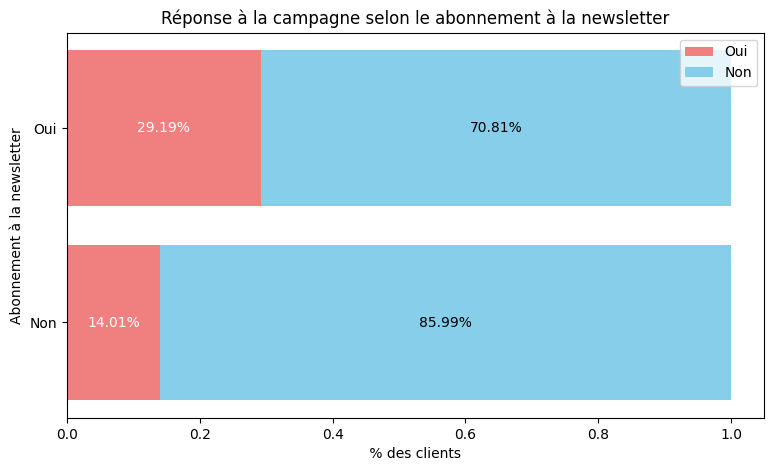

In [ ]:
#3
oui = tableauBp['Oui'].sort_values(ascending=True)
non = tableauBp['Non'].sort_values(ascending=False)
plt.figure(figsize=(9, 5))
plt.barh(
    y=oui.index,
    width=oui.values,
    color='lightcoral'
)
plt.barh(
    y=non.index,
    width=non.values,
    left=oui.values,
    color='skyblue'
)
for i in range(len(oui)):
    plt.text(
        oui.values[i] / 2,
        i,
        f"{oui.values[i]:.2%}",
        ha='center',
        va='center',
        color='white',
        fontsize=10
    )
    plt.text(
        oui.values[i] + non.values[i] / 2,
        i,
        f"{non.values[i]:.2%}",
        ha='center',
        va='center',
        color='black',
        fontsize=10
    )
plt.title("Réponse à la campagne selon le abonnement à la newsletter")
plt.xlabel(" % des clients ")
plt.ylabel("Abonnement à la newsletter")
plt.legend(["Oui", "Non"], loc='upper right')

In [ ]:
#4
chi2, p_value, ddl, effectifs_theoriques = chi2_contingency(tableauB)

print(f"Statistique Khi-2 : {chi2:.4f}")
print(f"Valeur p (p-value) : {p_value:.4f}")
print(f"Degrés de liberté : {ddl}")
print("Effectifs théoriques :\n", effectifs_theoriques)

Statistique Khi-2 : 40.2347
Valeur p (p-value) : 0.0000
Degrés de liberté : 1
Effectifs théoriques :
 [[488.52 132.48]
 [455.48 123.52]]


In [ ]:
#5
v_cramer2 = association(tableauB, method="cramer")
print(f"V de Cramér : {v_cramer2:.4f}")

V de Cramér : 0.1851


### 3.3.3 — Cas B : les abonnés répondent-ils plus ?

Oui. Le taux de réponse des abonnés à la newsletter est de 29,19 %, contre 14,01 % pour les non-abonnés

### C. sexe × reponse_campagne 

In [ ]:
#1
tableauC = pd.crosstab(df['sexe'], df['reponse_campagne'])
tableauC

reponse_campagne,Non,Oui
sexe,,
Femme,504,142
Homme,440,114


In [ ]:
#2
tableauCp = pd.crosstab(df['sexe'], df['reponse_campagne'], normalize='index')
tableauCp

reponse_campagne,Non,Oui
sexe,,
Femme,0.780186,0.219814
Homme,0.794224,0.205776


In [ ]:
#3
chi2, p_value, ddl, effectifs_theoriques = chi2_contingency(tableauC)

print(f"Statistique Khi-2 : {chi2:.4f}")
print(f"Valeur p (p-value) : {p_value:.4f}")
print(f"Degrés de liberté : {ddl}")
print("Effectifs théoriques :\n", effectifs_theoriques)

Statistique Khi-2 : 0.2716
Valeur p (p-value) : 0.6023
Degrés de liberté : 1
Effectifs théoriques :
 [[508.18666667 137.81333333]
 [435.81333333 118.18666667]]


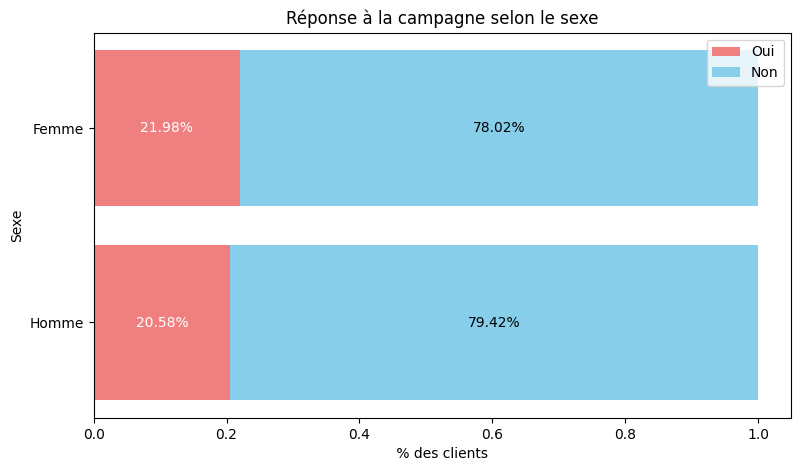

In [ ]:
#4
oui = tableauCp['Oui'].sort_values(ascending=True)
non = tableauCp['Non'].sort_values(ascending=False)
plt.figure(figsize=(9, 5))
plt.barh(
    y=oui.index,
    width=oui.values,
    color='lightcoral'
)
plt.barh(
    y=non.index,
    width=non.values,
    left=oui.values,
    color='skyblue'
)
for i in range(len(oui)):
    plt.text(
        oui.values[i] / 2,
        i,
        f"{oui.values[i]:.2%}",
        ha='center',
        va='center',
        color='white',
        fontsize=10
    )
    plt.text(
        oui.values[i] + non.values[i] / 2,
        i,
        f"{non.values[i]:.2%}",
        ha='center',
        va='center',
        color='black',
        fontsize=10
    )
plt.title("Réponse à la campagne selon le sexe")
plt.xlabel(" % des clients ")
plt.ylabel("Sexe")
plt.legend(["Oui", "Non"], loc='upper right')

In [ ]:
#5
v_cramer3 = association(tableauC, method="cramer")
print(f"V de Cramér : {v_cramer3:.4f}")

V de Cramér : 0.0171


### Q3.3.4 Cas C : le sexe influence-t-il la réponse à la campagne ?
non le sexe n'a aucune influence directe au reponse de la compagne, La p-value est de 0.6023, supérieure à 0.05. Il n'existe pas de relation statistiquement significativE

### D. tranche d'âge × canal_acquisition 

In [ ]:
df['tranche_age'] = pd.cut(df['age'], bins = [17,29,44,70], labels = ['18-29','30-44','45-70'])

In [ ]:
#1
tableauD = pd.crosstab(df['tranche_age'], df['canal_acquisition'])
tableauD

canal_acquisition,Email,Moteur de recherche,Parrainage,Publicite TV,Reseaux sociaux
tranche_age,,,,,
18-29,37,59,53,24,149
30-44,111,189,87,65,144
45-70,99,77,31,50,25


In [ ]:
#2
tableauDp = pd.crosstab(df['tranche_age'], df['canal_acquisition'], normalize = 'index')
tableauDp

canal_acquisition,Email,Moteur de recherche,Parrainage,Publicite TV,Reseaux sociaux
tranche_age,,,,,
18-29,0.114907,0.183230,0.164596,0.074534,0.462733
30-44,0.186242,0.317114,0.145973,0.109060,0.241611
45-70,0.351064,0.273050,0.109929,0.177305,0.088652


In [ ]:
chi2, p_value, ddl, effectifs_theoriques = chi2_contingency(tableauD)

print(f"Statistique Khi-2 : {chi2:.4f}")
print(f"Valeur p (p-value) : {p_value}")
print(f"Degrés de liberté : {ddl}")
print("Effectifs théoriques :\n", effectifs_theoriques)

Statistique Khi-2 : 156.0467
Valeur p (p-value) : 1.0720654165030744e-29
Degrés de liberté : 8
Effectifs théoriques :
 [[ 66.27833333  87.20833333  45.885       37.29833333  85.33      ]
 [122.67666667 161.41666667  84.93        69.03666667 157.94      ]
 [ 58.045       76.375       40.185       32.665       74.73      ]]


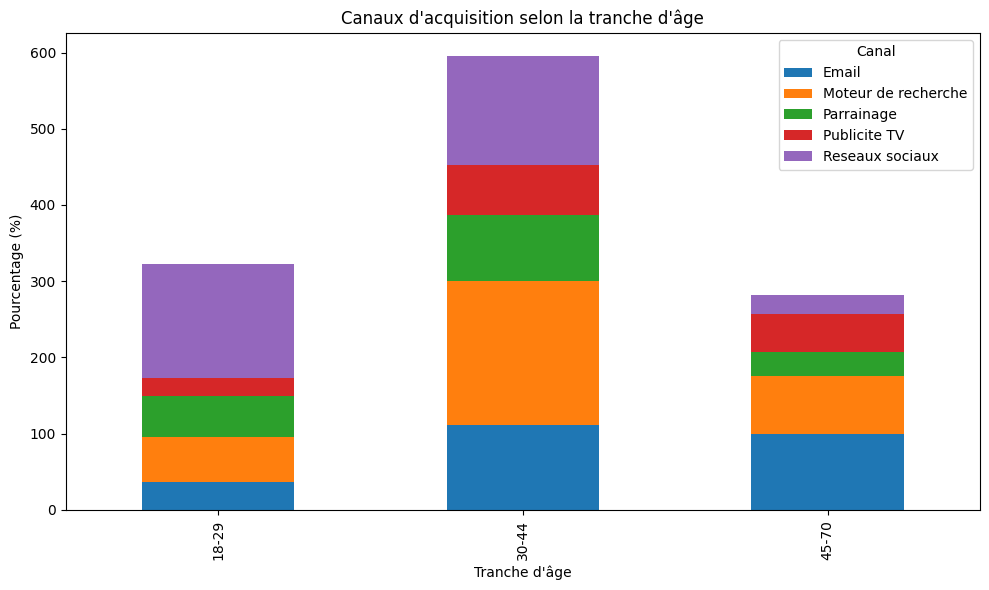

In [ ]:
#4
tableauD.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6)
)

plt.title("Canaux d'acquisition selon la tranche d'âge")
plt.xlabel("Tranche d'âge")
plt.ylabel("Pourcentage (%)")
plt.legend(title="Canal")
plt.tight_layout()
plt.show()

In [ ]:
#5
v_cramer4 = association(tableauD, method="cramer")
print(f"V de Cramér : {v_cramer4:.4f}")

V de Cramér : 0.2550


### Q3.3.5 Cas D : quel est le canal dominant chez les 18-29 ans ? chez les 45-70 ans ? Le lien est-il significatif ?

Chez les 18-29 ans les réseaux sociaux sont dominants avec 46.27 % et chez les 45-70 ans c'est l'Email avec 35.11 %<br>Le test du khi-deux donne une p-value de 1,07 × 10⁻²⁹ ce qui montre une association statistiquement significative 

### Q3.3.6 Pourquoi faut-il comparer les pourcentages en ligne et non les effectifs bruts ?
car les groupes n'ont pas la même taille, les effectives brutes no sont pas efficace mais les pourcentages en ligne permettent de comparer les proportions au sein de chaque groupe

# 4.	Analyse trivariée

## 4.1	Deux quantitatives + une qualitative : achats, dépense et segment

In [ ]:
#1.	Tracer le nuage nb_achats_an (x) × depense_annuelle (y), en coloriant les points par segment_client.
fig = px.scatter(
    df,
    x='nb_achats_an',
    y='depense_annuelle',
    color='segment_client',
    opacity=0.6,
    title="Relation entre achats et dépense annuelle selon le segment",
    labels={
        'nb_achats_an': "Nombre d'achats par an",
        'depense_annuelle': "Dépense annuelle (MAD)",
        'segment_client': "Segment"
    })

fig.show()

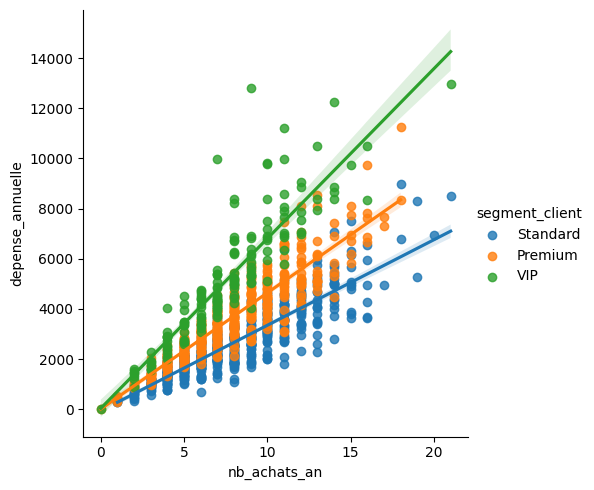

In [ ]:
#2.	Pour chaque segment, ajuster une droite de régression et la tracer dans la couleur du segment (ou utiliser sns.lmplot(..., hue=...)).
sns.lmplot(data=df, x='nb_achats_an', y='depense_annuelle',
           hue='segment_client')

plt.show()

In [ ]:
#3.	Construire un tableau : pour chaque segment, la pente de la droite, la corrélation achats–dépense, le nombre moyen d'achats et le panier moyen.
Segment = []

for segment, groupe in df.groupby('segment_client'):

    x = groupe['nb_achats_an']
    y = groupe['depense_annuelle']

    pente, intercept = np.polyfit(x, y, 1)
    correlation = x.corr(y)

    Segment.append({
        'Segment': segment,
        'Pente': pente,
        'Correlation': correlation,
        'Achats_moyens': x.mean(),
        'Panier_moyen': groupe['panier_moyen'].mean()
    })

tableau1 = pd.DataFrame(Segment)

display(tableau1.round(2))

,Segment,Pente,Correlation,Achats_moyens,Panier_moyen
0,Premium,463.30,0.91,7.80,464.95
1,Standard,341.07,0.88,7.99,333.57
2,VIP,677.19,0.89,7.56,678.04


### Q4.1.1 La relation achats–dépense est-elle positive dans les trois segments ?
d'apres 3 la correlation est positive dans les trois segments , ce qui signifie que plus le nombre d'achats augmente, plus la depense annuelle augmente pour tous les segments
### Q4.1.2 Les trois droites ont-elles la même pente ? Que représente concrètement la pente ?
non , les pentes d'apres (2) sont differentes , la pente represente l'augmentation estimee de la depense annuelle en MAD
### Q4.1.3 Les VIP achètent-ils plus souvent que les Standard ? Alors pourquoi dépensent-ils plus ?
non,d'apres 3 les VIP (7.56) achetent moins que les Standard (7.99)<br>les VIP depensent plus car leur panier moyen est plus élevé

## 4.2	Deux qualitatives + une binaire : canal, newsletter et réponse

In [ ]:
#1.	Créer une colonne numérique reponse_num valant 1 pour « Oui » et 0 pour « Non » (la moyenne d'une variable 0/1 est un taux).
df['reponse_num'] = df['reponse_campagne'].map({'Oui': 1, 'Non': 0})

In [ ]:
#2.	Construire un tableau à double entrée avec pd.pivot_table : lignes = canal, colonnes = newsletter, valeurs = taux de réponse en %.
tableau = pd.pivot_table(
    df,
    index='canal_acquisition',
    columns='abonne_newsletter',
    values='reponse_num',
    aggfunc='mean'
) * 100

tableau.round(2)

abonne_newsletter,Non,Oui
canal_acquisition,,
Email,23.93,34.62
Moteur de recherche,13.14,33.33
Parrainage,18.29,32.58
Publicite TV,7.79,9.68
Reseaux sociaux,8.82,26.35


In [ ]:
#3.	Afficher aussi les effectifs de chaque case (pd.crosstab) pour vérifier qu'aucune case n'est trop petite.
effectifs = pd.crosstab(df['canal_acquisition'], df['abonne_newsletter'])
effectifs

abonne_newsletter,Non,Oui
canal_acquisition,,
Email,117,130
Moteur de recherche,175,150
Parrainage,82,89
Publicite TV,77,62
Reseaux sociaux,170,148


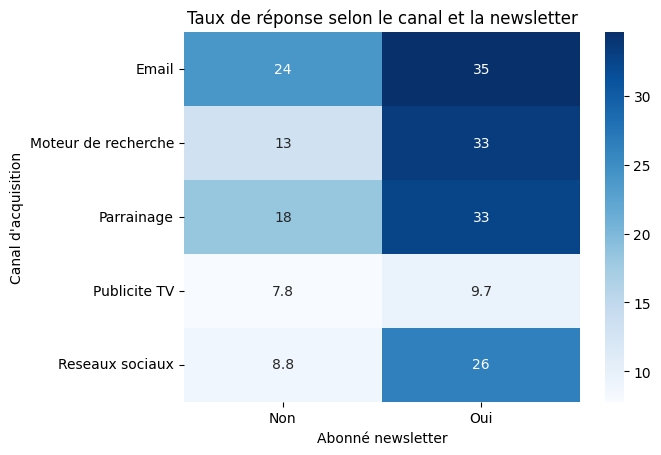

In [ ]:
#4.	Représenter le tableau en heatmap annotée (palette d'une seule couleur, du clair au foncé).
sns.heatmap(tableau, annot=True, cmap='Blues')
plt.title("Taux de réponse selon le canal et la newsletter")
plt.xlabel("Abonné newsletter")
plt.ylabel("Canal d'acquisition")
plt.show()

In [ ]:
#5.	Calculer, pour chaque canal, l'écart en points entre abonnés et non-abonnés.
ecart = tableau['Oui'] - tableau['Non']

display(ecart.round(2))

canal_acquisition
Email                  10.68
Moteur de recherche    20.19
Parrainage             14.29
Publicite TV            1.89
Reseaux sociaux        17.53
dtype: float64

### Q4.2.1 La newsletter augmente-t-elle le taux de réponse dans tous les canaux ?
le heatmap montre que oui les abonnes newsletter augmente le taux de reponse dans tous les canaux
### Q4.2.2 Dans quel canal l'effet de la newsletter est-il le plus fort ? le plus faible ?
d'apres le heatmap l'effet de la newsletter est plus fort pour le moteur de recherche (20.19 d'ecart) et le plus faible pour publicite TV(1.89 d'ecart)
### Q4.2.3 Peut-on parler d'interaction entre canal et newsletter ? Justifiez.
Oui , on peut parler d'interaction entre canal et newsletter , l'écart est très élevé dans un canal et faible dans un autre
### Q4.2.4 Quelle est la plus petite case (effectif) ? Le tableau est-il fiable ?
d'apres le heatmap la plus petite case est publicite TV, 

## 4.3	Une quantitative + deux qualitatives : dépense, niveau d'étude et sexe

In [ ]:
#1.	Construire le tableau des dépenses moyennes avec pivot_table : lignes = niveau_etude (dans l'ordre), colonnes = sexe.
tableau2 = pd.pivot_table(
    df,
    index='niveau_etude',
    columns='sexe',
    values='depense_annuelle',
    aggfunc='mean'
).reindex(['Bac', 'Licence', 'Master', 'Doctorat'])

display(tableau2.round(2))

sexe,Femme,Homme
niveau_etude,,
Bac,2645.09,2792.04
Licence,3241.37,3296.27
Master,3876.43,3891.39
Doctorat,4306.57,4396.49


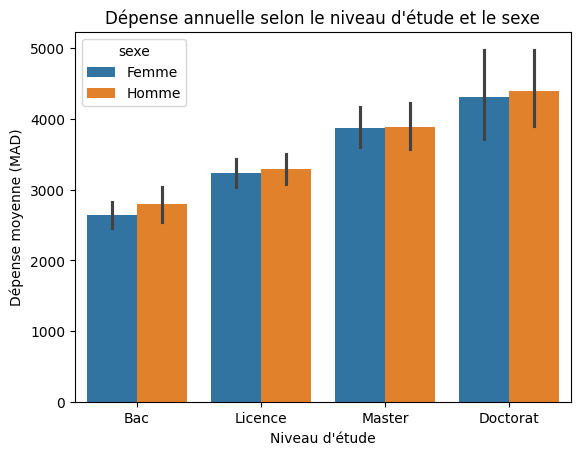

In [ ]:
#2.	Tracer un diagramme en barres groupées (x = niveau d'étude, hauteur = dépense moyenne, couleur = sexe).
ordre = ['Bac', 'Licence', 'Master', 'Doctorat']
sns.barplot(
    data=df,
    x='niveau_etude',
    y='depense_annuelle',
    hue='sexe',
    order=ordre
)

plt.title("Dépense annuelle selon le niveau d'étude et le sexe")
plt.xlabel("Niveau d'étude")
plt.ylabel("Dépense moyenne (MAD)")
plt.show()

In [ ]:
#3.	Calculer, pour comparaison, le revenu mensuel moyen par niveau d'étude.
revenu = df.groupby('niveau_etude')['revenu_mensuel'].mean()

revenu.round(2)

niveau_etude
Bac          5759.27
Doctorat    12025.70
Licence      7583.47
Master       9610.45
Name: revenu_mensuel, dtype: float64

### Q4.3.1 Dans chaque niveau d'étude, l'écart de dépense entre femmes et hommes est-il important ?
l'ecart de depense d'apres le diagramme et le tableau faible dans tous les niveaux d'étude et le moins faible c'est le bac
### Q4.3.2 Comment évolue la dépense moyenne du Bac au Doctorat ?
D'apres 3 la depense moyenne s'augmente du Bac au Doctorat, une evolution positive.
### Q4.3.3 Le niveau d'étude agit-il directement sur la dépense ? Proposez une variable intermédiaire et vérifiez-la.
oui , le niveau d'etude agit sur la depense <br>parceque son revenu est plus élevé<br>On propose le revenu moyen qui  augmente avec le niveau d'etude

# 5.	Analyse multivariée

## 5.1	Matrice de corrélation

In [ ]:
#1.	Calculer la matrice de corrélation de Pearson des 9 variables de var_quanti (df[var_quanti].corr()).
matrice = var_quanti.corr()
matrice.round(2)

,age,revenu_mensuel,nb_visites_mois,duree_session_min,nb_achats_an,panier_moyen,depense_annuelle,taux_ouverture_email,note_satisfaction
age,1.00,0.26,-0.37,0.00,-0.21,0.21,-0.03,-0.02,-0.06
revenu_mensuel,0.26,1.00,-0.12,-0.05,-0.04,0.91,0.53,-0.03,-0.04
nb_visites_mois,-0.37,-0.12,1.00,0.01,0.57,-0.10,0.37,0.08,0.18
duree_session_min,0.00,-0.05,0.01,1.00,-0.02,-0.05,-0.04,0.02,-0.01
nb_achats_an,-0.21,-0.04,0.57,-0.02,1.00,-0.03,0.75,0.08,0.28
panier_moyen,0.21,0.91,-0.10,-0.05,-0.03,1.00,0.60,-0.04,-0.03
depense_annuelle,-0.03,0.53,0.37,-0.04,0.75,0.60,1.00,0.05,0.19
taux_ouverture_email,-0.02,-0.03,0.08,0.02,0.08,-0.04,0.05,1.00,0.06
note_satisfaction,-0.06,-0.04,0.18,-0.01,0.28,-0.03,0.19,0.06,1.00


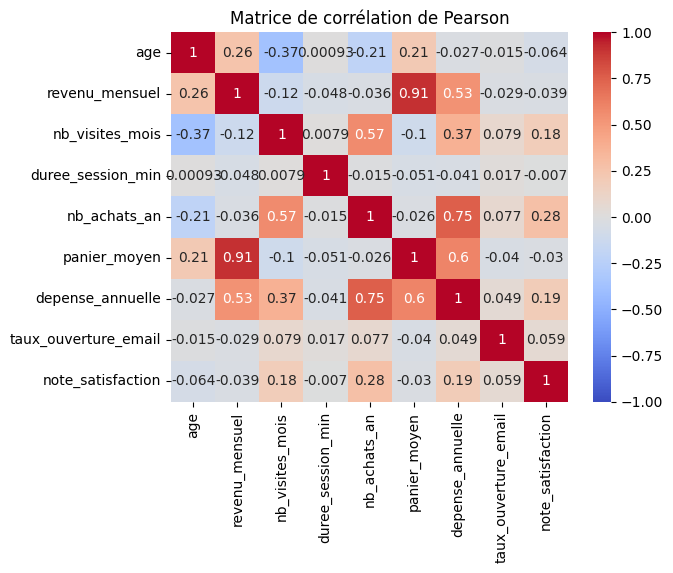

In [ ]:
#2.	L'afficher en heatmap annotée (palette divergente centrée sur 0, bornes −1 et +1).
sns.heatmap(matrice, annot=True, cmap='coolwarm',
            center=0, vmin=-1, vmax=1)

plt.title("Matrice de corrélation de Pearson")
plt.show()

In [ ]:
#3.	Lister les 5 couples ayant les corrélations les plus fortes en valeur absolue.
top5 = matrice.where(np.triu(np.ones(matrice.shape), k=1).astype(bool)).stack()

display(top5.abs().nlargest(5))

revenu_mensuel   panier_moyen        0.910544
nb_achats_an     depense_annuelle    0.751318
panier_moyen     depense_annuelle    0.595205
nb_visites_mois  nb_achats_an        0.567747
revenu_mensuel   depense_annuelle    0.532084
dtype: float64

In [ ]:
#4.	Repérer les variables isolées (toutes leurs corrélations sont inférieures à 0,1 en valeur absolue).
isolées = matrice.abs().lt(0.1)
isolées = isolées.sum(axis=1) == len(matrice.columns) - 1
matrice.index[isolées].tolist()

['duree_session_min', 'taux_ouverture_email']

### Q5.1.1 Quels sont les 3 couples les plus corrélés ? Lequel est logique « par construction » ?
En se basant sur 3 , les 3 couples les plus corrélés sont : <br>revenu_mensuel x panier_moyen (0.910544), <br>nb_achats_an x depense_annuelle (0.751318),
<br>panier_moyen x depense_annuelle (0.595205)<br>
Le couple nb_achats_an et depense_annuelle est fortement corrélé, C'est une relation logique par construction.

### Q5.1.2 Deux variables très corrélées (|r| > 0,9) apportent-elles des informations différentes ? Quel problème cela pose-t-il dans un modèle ?
Cela peut provoquer un problème de **multicolinéarité** dans les modèles de régression : les coefficients deviennent moins stables et difficiles à interpréter.
### Q5.1.3 Quelles variables sont isolées ? Que signifie cela pour l'analyse ?
d'apres 4, Le variable isolée ['duree_session_min'] a une corrélation inférieure à 0,1 <br>
Cela signifie qu'elles ont peu de relations linéaires avec les autres variables étudiées. Elles peuvent apporter une information complémentaire.
### Q5.1.4 Quelle variable est négativement corrélée avec l'activité sur le site ?
Dans les résultats précédents, age présente une corrélation négative avec nb_visites_mois (r = -0,375). Cela signifie que les clients plus âgés tendent à effectuer moins de visites sur le site.

## 5.2	Pairplot

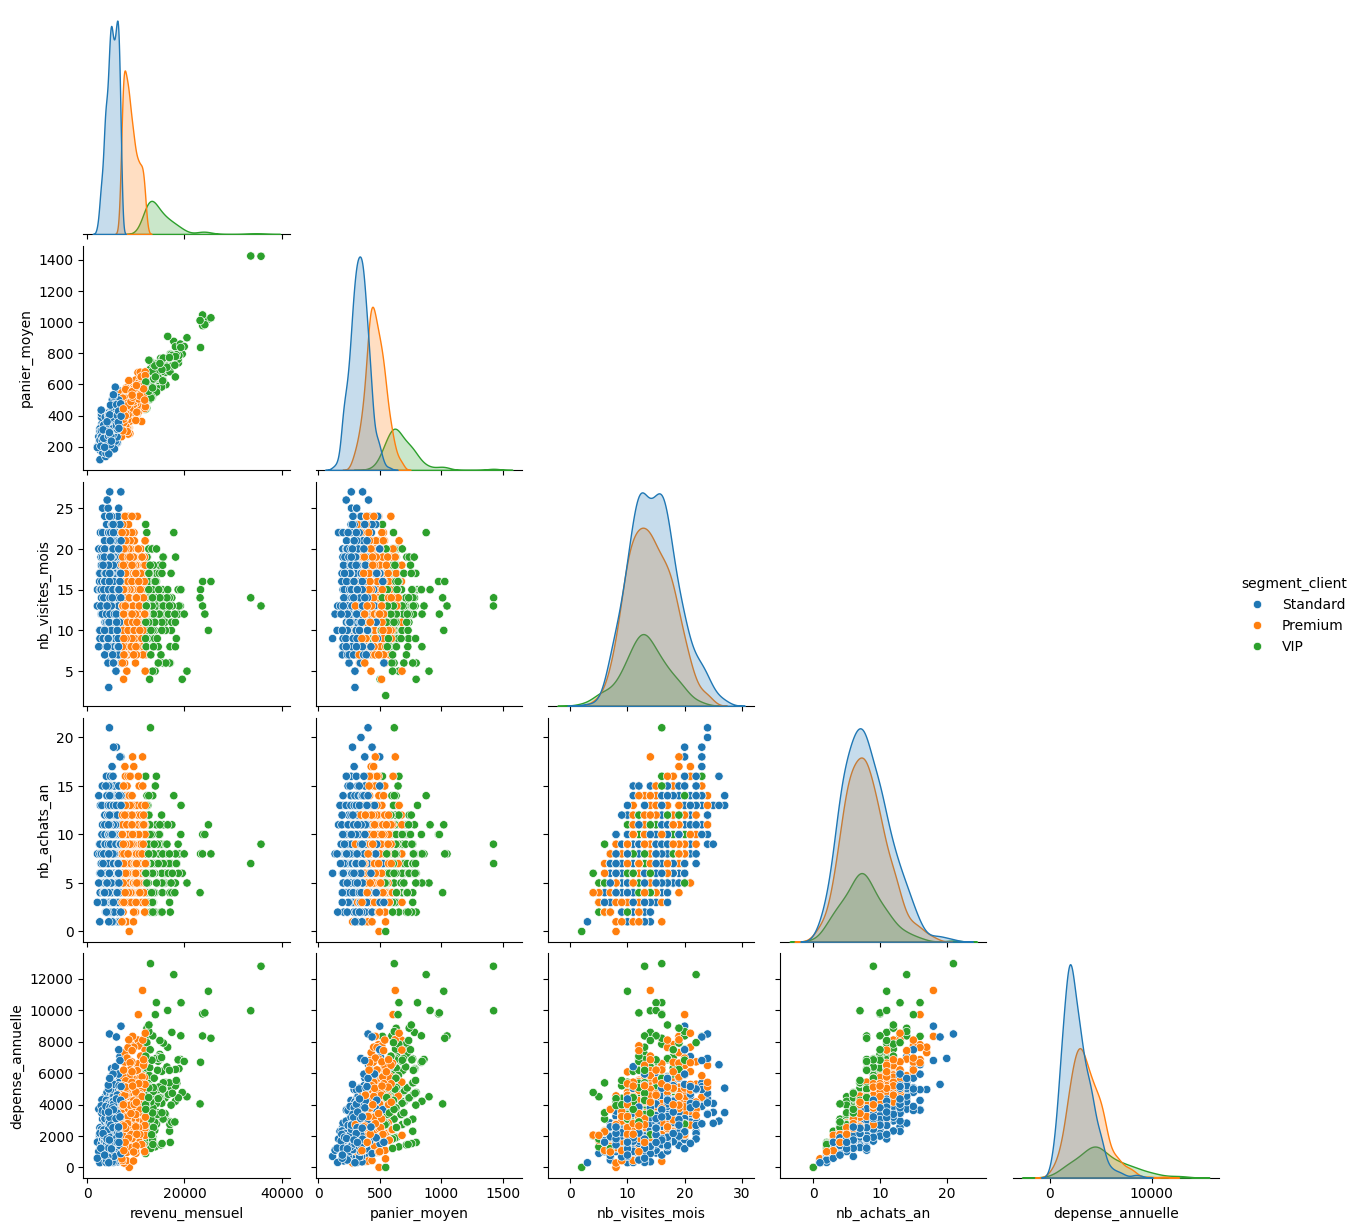

In [ ]:
#1.	Tracer un pairplot (sns.pairplot) des variables revenu_mensuel, panier_moyen, nb_visites_mois, nb_achats_an, depense_annuelle, coloré par segment_client (option corner=True).
variables = [
    'revenu_mensuel',
    'panier_moyen',
    'nb_visites_mois',
    'nb_achats_an',
    'depense_annuelle'
]

sns.pairplot(
    df[variables + ['segment_client']],
    hue='segment_client',
    corner=True
)

plt.show()

### Q5.2.1 Sur quels nuages les trois segments sont-ils bien séparés ? Pourquoi est-ce logique ?
Les trois segments sont parfaitement séparés selon le revenu mensuel (Standard, Premium et VIP), car cette variable est utilisée pour définir les segments
### Q5.2.2 Sur la diagonale, quelles distributions sont asymétriques ?  
Les distributions de trois variables présentent une asymétrie à droite (skewness positive)

## 5.3	Analyse en Composantes Principales (ACP)

In [ ]:
#2.	Standardiser avec StandardScaler puis ajuster PCA() (scikit-learn) sur toutes les composantes.
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

scaler = StandardScaler()
X_scaled = scaler.fit_transform(data)

pca = PCA()
X_pca = pca.fit_transform(X_scaled)

In [ ]:
#3.	Récupérer les valeurs propres (explained_variance_), les % de variance (explained_variance_ratio_) et leur cumul.
valeurs = pca.explained_variance_
variance = pca.explained_variance_ratio_ * 100
cumul = variance.cumsum()

tableau_acp = pd.DataFrame({
    'Valeur propre': valeurs,
    'Variance (%)': variance,
    'Cumul (%)': cumul
}, index=[f'F{i+1}' for i in range(len(valeurs))])

tableau_acp.round(2)

,Valeur propre,Variance (%),Cumul (%)
F1,2.55,28.35,28.35
F2,2.19,24.31,52.65
F3,1.02,11.37,64.02
F4,0.99,10.94,74.96
F5,0.92,10.17,85.13
F6,0.75,8.29,93.43
F7,0.46,5.13,98.56
F8,0.10,1.14,99.70
F9,0.03,0.30,100.00


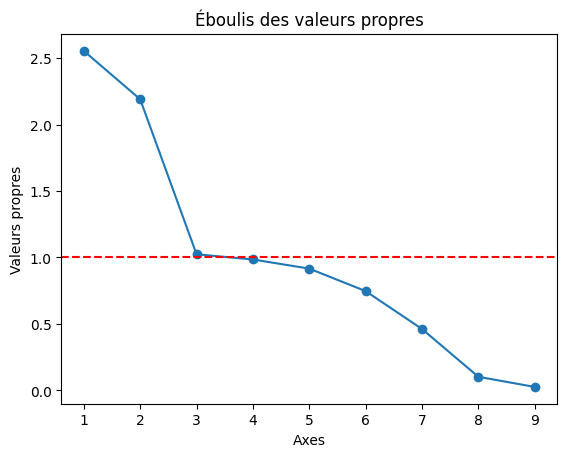

In [ ]:
#4.	Tracer l'éboulis des valeurs propres avec une ligne horizontale à λ = 1.
plt.plot(range(1, len(valeurs) + 1), valeurs, marker='o')

plt.axhline(y=1, color='red', linestyle='--')
plt.xlabel("Axes")
plt.ylabel("Valeurs propres")
plt.title("Éboulis des valeurs propres")
plt.xticks(range(1, len(valeurs) + 1))
plt.show()

In [ ]:
#5.	Calculer les corrélations variables–axes : components_ × √(valeur propre), et les présenter dans un tableau pour F1, F2, F3.
var_quanti = [
    'age',
    'revenu_mensuel',
    'nb_visites_mois',
    'duree_session_min',
    'nb_achats_an',
    'panier_moyen',
    'depense_annuelle',
    'taux_ouverture_email',
    'note_satisfaction'
]

In [130]:
data = df[var_quanti].dropna()

print(data.shape)

(1164, 9)


In [ ]:
correlations = pca.components_.T * np.sqrt(pca.explained_variance_)

tableau_corr = pd.DataFrame(
    correlations[:, :3],
    index=var_quanti,
    columns=['F1', 'F2', 'F3']
)

display(tableau_corr.round(2))

,F1,F2,F3
age,0.07,-0.59,0.29
revenu_mensuel,0.75,-0.58,0.00
nb_visites_mois,0.33,0.73,-0.10
duree_session_min,-0.08,0.05,0.57
nb_achats_an,0.58,0.68,-0.01
panier_moyen,0.78,-0.55,-0.02
depense_annuelle,0.94,0.19,-0.01
taux_ouverture_email,0.05,0.16,0.73
note_satisfaction,0.22,0.37,0.27


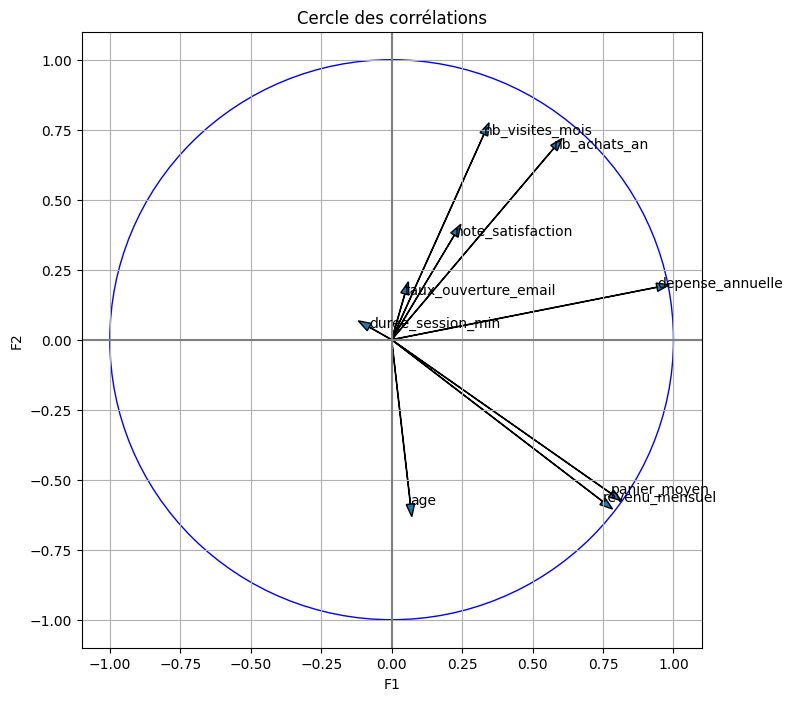

In [ ]:
#6.	Tracer le cercle des corrélations (F1, F2).
plt.figure(figsize=(8, 8))

cercle = plt.Circle((0, 0), 1, color='blue', fill=False)
plt.gca().add_patch(cercle)

for variable in var_quanti:
    x = tableau_corr.loc[variable, 'F1']
    y = tableau_corr.loc[variable, 'F2']

    plt.arrow(0, 0, x, y, head_width=0.03)
    plt.text(x, y, variable)

plt.axhline(0, color='gray')
plt.axvline(0, color='gray')

plt.xlabel('F1')
plt.ylabel('F2')
plt.title('Cercle des corrélations')
plt.xlim(-1.1, 1.1)
plt.ylim(-1.1, 1.1)
plt.grid()
plt.show()

In [ ]:
#7.	Projeter les clients sur F1–F2 (transform), les colorer par segment et calculer la position moyenne de chaque segment.
projection = pd.DataFrame(X_pca[:, :2], columns=['F1', 'F2'])

projection['segment_client'] = df.loc[data.index, 'segment_client'].values

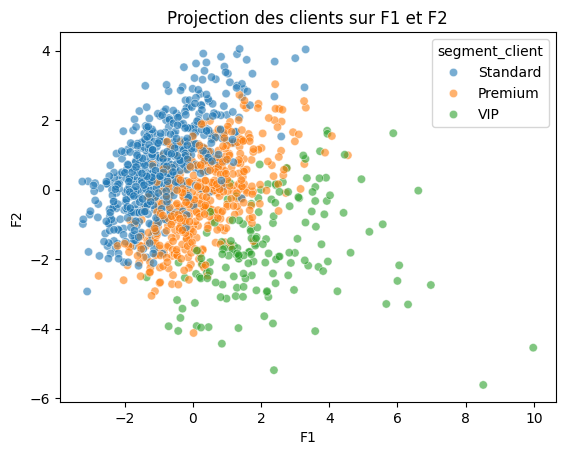

In [149]:
sns.scatterplot(
    data=projection,
    x='F1',
    y='F2',
    hue='segment_client',
    alpha=0.6
)

plt.title("Projection des clients sur F1 et F2")
plt.show()

In [150]:
moyennes = projection.groupby('segment_client')[['F1', 'F2']].mean()

display(moyennes.round(2))

,F1,F2
segment_client,,
Premium,0.31,-0.22
Standard,-0.88,0.65
VIP,2.21,-1.67


In [151]:
qualite = tableau_corr['F1']**2 + tableau_corr['F2']**2

display(qualite.sort_values().round(2))

duree_session_min       0.01
taux_ouverture_email    0.03
note_satisfaction       0.19
age                     0.35
nb_visites_mois         0.65
nb_achats_an            0.80
revenu_mensuel          0.89
panier_moyen            0.91
depense_annuelle        0.92
dtype: float64

### Q5.3.1 Quelle part de l'information est portée par F1 ? par F2 ? par le plan F1–F2 ?
d'apres la projecton des clients sur F1-F2:
- F1 explique 25,78 % de l'information<br>
- F2 explique 22,01 % de l'information<br>
- Le plan F1–F2 explique 47,79 % de l'information<br>
F1–F2 représente presque la moitié de l'information du dataset
### Q5.3.2 Combien d'axes retenir selon la règle de Kaiser ? Le 3e axe est-il convaincant ?
La règle de Kaiser consiste à retenir les axes dont la valeur propre est supérieure à 1
- F1 = 2,58
- F2 = 2,20
- F3 = 1,24
- F4 = 1,00 (à la limite, mais pas strictement supérieur à 1)
On retient donc 3 axes : F1, F2 et F3.

Le troisième axe est intéressant, car sa valeur propre est de 1,24, supérieure à 1. Il explique 12,44 % de l'information supplémentaire.
### Q5.3.3 Quelles variables sont les plus liées à F1 ? Proposez un nom pour cet axe. 
les variables les plus liees à F1 sont :<br>
depense_annuelle : 0,94<br>
panier_moyen : 0,78<br>
revenu_mensuel : 0,75<br>
nb_achats_an : 0,58<br>
on propose le nom de : axe du pouvoir d'achat et de la valeur client
### Q5.3.4 Quelles variables s'opposent sur F2 ? Proposez un nom pour cet axe.
Sur F2, on observe deux groupes :<br>
positif : nb_visites_mois (0,73), nb_achats_an (0,68) et note_satisfaction (0,37).
négatif : age (-0,59), revenu_mensuel (-0,58) et panier_moyen (-0,55).<br>
nom proposé : Axe opposant l'activité client au profil âge/revenu/panier moyen.
### Q5.3.5 Quelles variables sont mal représentées dans le plan F1–F2 ? Sur quel axe apparaissent-elles ?
Les variables duree_session_min, taux_ouverture_email et note_satisfaction sont mal représentées sur le plan F1–F2. Elles sont davantage liées à l'axe F3, surtout les deux premières.
### Q5.3.6 Où se placent en moyenne les clients Standard, Premium et VIP dans le plan F1–F2 ?
Les clients VIP se trouvent à droite et en bas du graphique. Les clients Standard se trouvent à gauche et en haut. Les clients Premium sont proches du centre du graphique.

## 5.4	Pour aller plus loin (facultatif)

### •	Réaliser une classification K-means sur les 3 premières coordonnées de l'ACP (essayer k = 3 à 5, méthode du coude) et décrire chaque groupe obtenu.

In [152]:
from sklearn.cluster import KMeans

X = X_pca[:, :3]

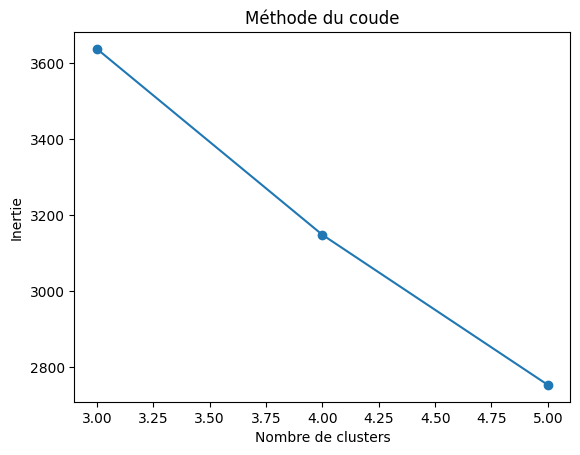

In [153]:
inerties = []

for k in range(3, 6):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X)
    inerties.append(km.inertia_)

plt.plot(range(3, 6), inerties, marker='o')
plt.xlabel("Nombre de clusters")
plt.ylabel("Inertie")
plt.title("Méthode du coude")
plt.show()

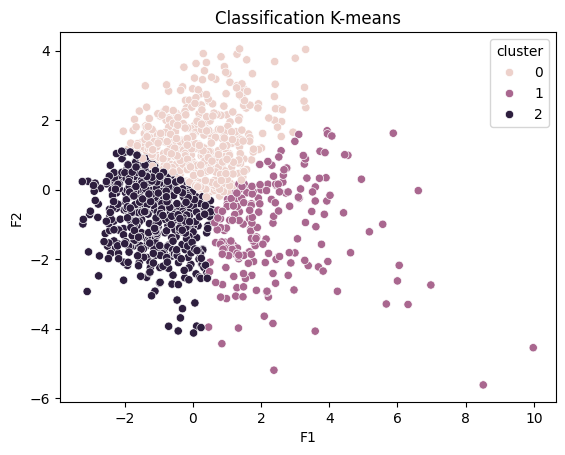

In [154]:
km = KMeans(n_clusters=3, random_state=42, n_init=10)

projection['cluster'] = km.fit_predict(X)

sns.scatterplot(data=projection, x='F1', y='F2', hue='cluster')
plt.title("Classification K-means")
plt.show()

In [155]:
data['cluster'] = projection['cluster'].values

display(data.groupby('cluster').mean().round(2))

,age,revenu_mensuel,nb_visites_mois,duree_session_min,nb_achats_an,panier_moyen,depense_annuelle,taux_ouverture_email,note_satisfaction
cluster,,,,,,,,,
0,31.63,6452.57,17.19,6.32,10.27,374.79,3830.27,29.91,3.63
1,41.20,13900.70,13.80,5.41,8.76,655.45,5665.79,27.00,3.29
2,39.33,7036.63,11.66,5.75,5.46,392.32,2103.73,25.76,2.89


Les clients sont répartis en 3 groupes selon leurs caractéristiques. Chaque groupe présente des différences en termes de revenu, de dépenses et d'activité.

### •	Construire une régression logistique pour prédire reponse_campagne à partir de taux_ouverture_email, abonne_newsletter, canal_acquisition et note_satisfaction. Les variables importantes sont-elles celles repérées en partie 3 ?

In [156]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

X = df[['taux_ouverture_email', 'note_satisfaction',
        'abonne_newsletter', 'canal_acquisition']]

y = df['reponse_campagne'].map({'Oui': 1, 'Non': 0})

donnees = pd.concat([X, y], axis=1).dropna()

X = donnees.drop(columns='reponse_campagne')
y = donnees['reponse_campagne']

In [157]:
X = pd.get_dummies(X, drop_first=True, dtype=int)

In [158]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

modele = LogisticRegression(max_iter=1000)
modele.fit(X_train, y_train)

pred = modele.predict(X_test)

In [159]:
from sklearn.metrics import classification_report

print(classification_report(y_test, pred))

              precision    recall  f1-score   support

           0       0.82      0.98      0.90       192
           1       0.67      0.17      0.27        48

    accuracy                           0.82       240
   macro avg       0.75      0.57      0.58       240
weighted avg       0.79      0.82      0.77       240



In [160]:
importance = pd.Series(abs(modele.coef_[0]), index=X.columns)
display(importance.sort_values(ascending=False))

canal_acquisition_Publicite TV           1.201551
canal_acquisition_Reseaux sociaux        0.540225
note_satisfaction                        0.465644
canal_acquisition_Moteur de recherche    0.309143
abonne_newsletter_Oui                    0.226436
canal_acquisition_Parrainage             0.075435
taux_ouverture_email                     0.039024
dtype: float64

Les variables ayant les coefficients les plus élevés en valeur absolue sont les plus importantes pour la prédiction. On peut les comparer avec les variables identifiées dans la partie 3.

### •	Calculer l'ancienneté (en mois) à partir de date_inscription et étudier son lien avec la dépense. 

In [169]:
df["date_inscription"].astype("datetime64[ns]")

0      2025-05-29
1      2022-09-19
2      2022-02-08
3      2024-07-23
4      2023-06-18
          ...    
1195   2023-07-13
1196   2023-01-27
1197   2025-09-16
1198   2023-11-08
1199   2022-04-08
Name: date_inscription, Length: 1200, dtype: datetime64[ns]

In [171]:
df["date_inscription"].info

<bound method Series.info of 0       2025-05-29
1       2022-09-19
2       2022-02-08
3       2024-07-23
4       2023-06-18
           ...    
1195    2023-07-13
1196    2023-01-27
1197    2025-09-16
1198    2023-11-08
1199    2022-04-08
Name: date_inscription, Length: 1200, dtype: object>

In [178]:
df['anciennete_mois'] = (
    (pd.Timestamp.today() - df['date_inscription']).dt.days / 30
).round(0)

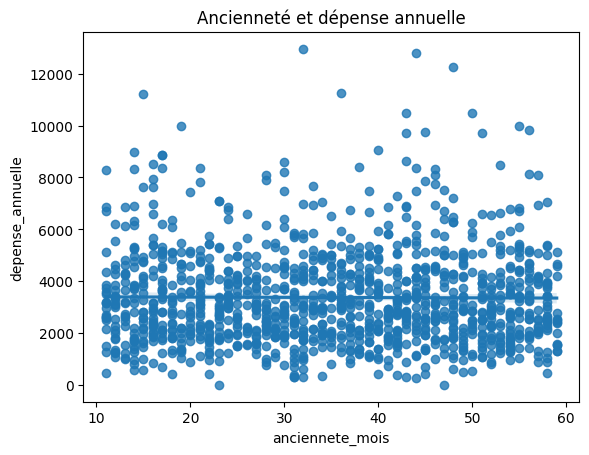

In [179]:
sns.regplot(data=df, x='anciennete_mois', y='depense_annuelle')

plt.title("Ancienneté et dépense annuelle")
plt.show()

In [180]:
df[['anciennete_mois', 'depense_annuelle']].corr()

,anciennete_mois,depense_annuelle
anciennete_mois,1.000000,-0.007197
depense_annuelle,-0.007197,1.000000


La corrélation est de -0,007, ce qui est très proche de 0. Cela indique qu'il n'existe pratiquement aucune relation linéaire entre l'ancienneté du client et sa dépense annuelle.